# UTS Graf Sains Data

| Nama | NIM | Kelas |
|---|---|---|
| Muh. Hilmy Fahrizal | 23031554125 | 2023D |

#### Alur pengerjaan

Data interaksi pengunjung toko online disimpan sebagai graf di Neo4j, dianalisis per periode waktu, lalu dipakai untuk merekomendasikan produk dan dievaluasi:

> Data interaksi → Graf Neo4j → Subgraph periode P1 → Matriks VSM (User × Item dan Item × User) → Pemilihan proyeksi → Similarity → KNN → Rekomendasi → Evaluasi (Hit@5 dan NDCG@5)

#### Isi notebook

| Bagian | Isi |
|---|---|
| 2.1 | Wrangling dan EDA: periode, filter, komposisi subgraph, VSM, proyeksi, similarity |
| 2.2 | Analytics: user acak, KNN, 3 item iklan, Hit@5 dan NDCG@5 |

#### Cara menjalankan
Jalankan sel dari atas ke bawah. Graf Neo4j harus sudah berisi hasil impor `events.csv` (lihat `Import_RetailRocket.ipynb`). Setiap paket di-*import* pada sel tempat paket itu pertama kali dipakai, dan tidak diimpor ulang pada sel-sel sesudahnya. Password Neo4j dibaca dari variabel lingkungan `NEO4J_PASSWORD` atau diminta saat sel koneksi dijalankan.

## 2. Soal UTS
### 2.1 Wrangling dan EDA (Maks. skor: 45)

#### No. 1: Menentukan dua periode waktu

> **Soal:** Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih per individu tidak boleh sama dalam 1 kelas.

**Pendekatan.** Seluruh data sudah berada di Neo4j (hasil impor `events.csv`). Periode waktu tidak membatasi impor, tetapi dipakai sebagai **filter interaksi** pada properti `timestamp` di setiap query. Data dibagi menjadi dua periode yang saling lepas:

| Periode | Rentang | Peran |
|---|---|---|
| **P1** (training) | 1 sampai 15 Agustus 2015 | membangun graf, matriks VSM, dan similarity |
| **P2** (testing) | 16 sampai 20 Agustus 2015 | kunci jawaban (*ground truth*) untuk mengevaluasi rekomendasi |

**Alasan pemilihan:**
- Data RetailRocket hanya mencakup **Mei sampai September 2015**, sehingga contoh periode pada soal (2023 dan 2024) tidak dapat dipakai karena tidak ada datanya.
- P2 berada **tepat setelah** P1 dan tidak tumpang tindih. Ini meniru kondisi nyata: perilaku masa lalu dipakai untuk memprediksi perilaku berikutnya, sekaligus mencegah kebocoran data (*data leakage*).
- Batas akhir setiap periode bersifat **eksklusif** (`< tanggal akhir + 1 hari`), dan seluruh waktu dalam **UTC**.

Sel berikut membaca `events.csv` dari folder `data/`, mengubah `timestamp` (milidetik) menjadi waktu yang terbaca, lalu mencetak rentang data dan jumlah interaksi per bulan sebagai dasar pemilihan periode.

In [ ]:
import os
import pandas as pd
from IPython.display import display

folder_data = "data" # folder tempat events.csv berada
csv_file_path = os.path.join(folder_data, "events.csv")

df = pd.read_csv(csv_file_path)
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms") # UTC

print("Rentang data:", df["datetime"].min(), "->", df["datetime"].max())
display(df.groupby(df["datetime"].dt.to_period("M")).size().to_frame("jumlah interaksi"))


Rentang data: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000


,jumlah interaksi
datetime,
2015-05,590652
2015-06,610393
2015-07,697984
2015-08,553362
2015-09,303710


**Hasil.** Data berawal pada 3 Mei 2015 dan berakhir pada 18 September 2015 (UTC). Jumlah interaksi per bulan:

| Bulan | Jumlah interaksi |
|---|---:|
| 2015-05 | 590.652 |
| 2015-06 | 610.393 |
| 2015-07 | 697.984 |
| 2015-08 | 553.362 |
| 2015-09 | 303.710 |

Bulan September lebih sedikit karena data hanya mencakup 18 hari. Agustus 2015 memiliki 553.362 interaksi, dan kedua periode (P1 dan P2) berada di dalam bulan ini.

**Menetapkan periode.** Sel berikut mendefinisikan `P1` dan `P2` (tanggal), kemudian fungsi `ke_ms` mengubah tanggal menjadi *unix timestamp* dalam milidetik (UTC) untuk menghasilkan batas `P1_start`, `P1_end`, `P2_start`, dan `P2_end`. Karena kolom `timestamp` bernilai milidetik, batas yang sama dipakai untuk menyaring data di pandas maupun di Cypher.

Grafik menampilkan jumlah interaksi per hari (garis abu-abu) dengan P1 diarsir biru dan P2 diarsir oranye.

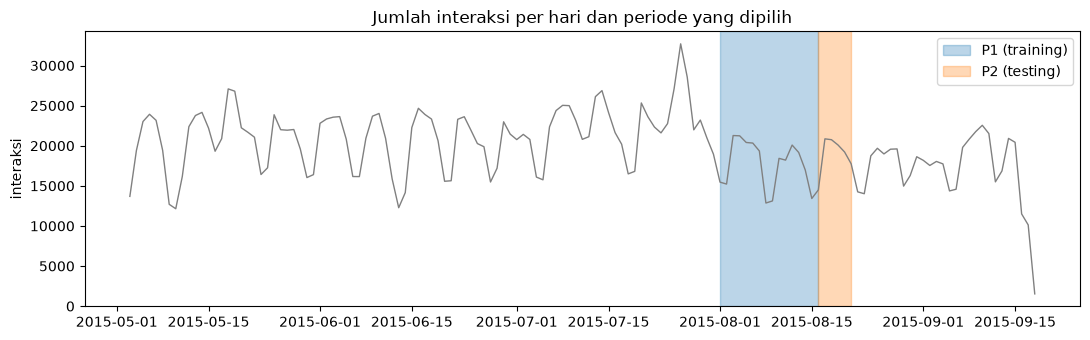

In [ ]:
import matplotlib.pyplot as plt

P1 = ("2015-08-01", "2015-08-15") # training
P2 = ("2015-08-16", "2015-08-20") # testing

def ke_ms(tgl):
    return int(round(pd.Timestamp(tgl).timestamp() * 1000))

DAY = 24 * 3600 * 1000
P1_start, P1_end = ke_ms(P1[0]), ke_ms(P1[1]) + DAY
P2_start, P2_end = ke_ms(P2[0]), ke_ms(P2[1]) + DAY

harian = df.set_index("datetime").resample("D").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(harian.index, harian.values, color="gray", lw=1)
for (a, b), warna, nama in [(P1, "tab:blue", "P1 (training)"), (P2, "tab:orange", "P2 (testing)")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=warna, alpha=0.3, label=nama)
ax.set_title("Jumlah interaksi per hari dan periode yang dipilih")
ax.set_ylabel("interaksi")
ax.legend()
plt.tight_layout()
plt.show()


Sel berikut mencetak keempat batas dalam milidetik beserta waktu aslinya sebagai pembuktian konversi.

In [3]:
from datetime import datetime, timezone

def tampil_ms(nama, ms):
    print(f"{nama:<9}: {ms}  ->  {datetime.fromtimestamp(ms / 1000, tz=timezone.utc)} UTC")

tampil_ms("P1_start", P1_start)
tampil_ms("P1_end", P1_end)
tampil_ms("P2_start", P2_start)
tampil_ms("P2_end", P2_end)


P1_start : 1438387200000  ->  2015-08-01 00:00:00+00:00 UTC
P1_end   : 1439683200000  ->  2015-08-16 00:00:00+00:00 UTC
P2_start : 1439683200000  ->  2015-08-16 00:00:00+00:00 UTC
P2_end   : 1440115200000  ->  2015-08-21 00:00:00+00:00 UTC


**Hasil.** Batas periode dalam *unix timestamp* milidetik (UTC):

| Variabel | Nilai (ms) | Waktu (UTC) |
|---|---:|---|
| `P1_start` | 1438387200000 | 2015-08-01 00:00:00 |
| `P1_end` | 1439683200000 | 2015-08-16 00:00:00 (eksklusif) |
| `P2_start` | 1439683200000 | 2015-08-16 00:00:00 |
| `P2_end` | 1440115200000 | 2015-08-21 00:00:00 (eksklusif) |

`P1_end` sama dengan `P2_start`: P1 berakhir tepat ketika P2 dimulai, tanpa celah maupun tumpang tindih.

#### No. 2: Menyaring `timestamp` dan menyimpan ke `.csv`

> **Soal:** Terapkan proses filter ini pada `timestamp` pada proses persiapan data, lalu simpan pada sebuah file `.csv`.

**Pendekatan.**
1. Setiap periode disaring dengan syarat `batas_awal <= timestamp < batas_akhir` (dalam milidetik) pada data `events.csv`.
2. Hasilnya disimpan sebagai `events_train.csv` (P1) dan `events_test.csv` (P2).
3. Syarat yang sama dipakai nanti pada Cypher (`WHERE r.timestamp >= $ts AND r.timestamp < $te`), sehingga filter di pandas dan di Neo4j konsisten.

Tabel yang dicetak merangkum ukuran tiap periode, serta jumlah visitor yang muncul pada **kedua** periode, karena hanya visitor tersebut yang dapat dievaluasi pada bagian Analytics.

In [4]:
def filter_period(df, t_start, t_end):
    """Ambil baris dengan t_start <= timestamp < t_end (milidetik)."""
    return df[(df["timestamp"] >= t_start) & (df["timestamp"] < t_end)]

train = filter_period(df, P1_start, P1_end).drop(columns="datetime")
test = filter_period(df, P2_start, P2_end).drop(columns="datetime")

train.to_csv(os.path.join(folder_data, "events_train.csv"), index=False)
test.to_csv(os.path.join(folder_data, "events_test.csv"), index=False)

ringkasan = pd.DataFrame({
    "Rentang": [f"{P1[0]} s.d. {P1[1]}", f"{P2[0]} s.d. {P2[1]}"],
    "Baris": [len(train), len(test)],
    "Visitor unik": [train["visitorid"].nunique(), test["visitorid"].nunique()],
    "Item unik": [train["itemid"].nunique(), test["itemid"].nunique()],
}, index=["P1 (training)", "P2 (testing)"])
display(ringkasan)
print("Visitor yang muncul di P1 dan P2:", len(set(train["visitorid"]) & set(test["visitorid"])))


,Rentang,Baris,Visitor unik,Item unik
P1 (training),2015-08-01 s.d. 2015-08-15,265509,153836,76078
P2 (testing),2015-08-16 s.d. 2015-08-20,95404,55754,39601


Visitor yang muncul di P1 dan P2: 3497


**Hasil.**

| Periode | Rentang | Baris | Visitor unik | Item unik |
|---|---|---:|---:|---:|
| P1 (training) | 2015-08-01 s.d. 2015-08-15 | 265.509 | 153.836 | 76.078 |
| P2 (testing) | 2015-08-16 s.d. 2015-08-20 | 95.404 | 55.754 | 39.601 |

Hanya **3.497 visitor** yang muncul di P1 maupun P2. Jumlah ini menjadi batas atas pengguna yang dapat dievaluasi pada bagian 2.2.

#### No. 3: Komposisi subgraph

> **Soal:** Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API. Jelaskan Cypher yang digunakan.

**Pendekatan.** Graf di Neo4j berisi seluruh interaksi, sedangkan *subgraph* yang dianalisis adalah interaksi pada **P1**. Empat query dijalankan lewat Python API (`session.run`) dan hasilnya dijadikan tabel:

| Query Cypher | Penjelasan |
|---|---|
| `MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah` | `MATCH (n)` mengambil semua simpul. `labels(n)[0]` adalah label (jenis) simpul, dan `count(*)` menghitung jumlahnya per label (setara `GROUP BY`). **Seluruh graf.** |
| `MATCH ()-[r]->() RETURN type(r) AS jenis, count(*) AS jumlah` | Pola `()-[r]->()` mengambil semua relasi berarah, dan `type(r)` adalah jenis relasinya. **Seluruh graf.** |
| `MATCH (v:Visitor)-[r]->(i:Item) WHERE r.timestamp >= $ts AND r.timestamp < $te RETURN count(DISTINCT v), count(DISTINCT i)` | `WHERE` membatasi relasi pada P1. `count(DISTINCT ...)` menghitung visitor dan item **unik** yang terlibat. **Subgraph P1, simpul.** |
| `MATCH (v:Visitor)-[r]->(i:Item) WHERE r.timestamp >= $ts AND r.timestamp < $te RETURN type(r), count(*)` | Filter yang sama, tetapi dikelompokkan per jenis relasi. **Subgraph P1, relasi.** |

Koneksi ke Neo4j (`GraphDatabase.driver(...)` dan `verify_connectivity()`) dibuat pada awal sel berikut. Password dibaca dari variabel lingkungan `NEO4J_PASSWORD`, atau diminta lewat `getpass` bila belum diset, sehingga tidak tertulis di notebook yang diunggah ke GitHub. Sel yang tidak mencetak pesan kesalahan berarti koneksi berhasil.

Sebagai verifikasi, jumlah visitor, item, dan baris pada `events_train.csv` dibandingkan dengan hasil Neo4j.

In [ ]:
import sys
import getpass
from neo4j import GraphDatabase

NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Password Neo4j: ")

try:
    driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

p1 = {"ts": P1_start, "te": P1_end}

q_full_simpul = "MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah"
q_full_relasi = "MATCH ()-[r]->() RETURN type(r) AS jenis, count(*) AS jumlah"

q_sub_simpul = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $ts AND r.timestamp < $te
RETURN count(DISTINCT v) AS Visitor, count(DISTINCT i) AS Item
"""
q_sub_relasi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $ts AND r.timestamp < $te
RETURN type(r) AS jenis, count(*) AS jumlah
"""

def query_df(q, **params):
    with driver.session() as session:
        return pd.DataFrame(session.run(q, **params).data())

# tabel simpul
full_simpul = query_df(q_full_simpul).set_index("jenis")["jumlah"]
sub_simpul = query_df(q_sub_simpul, **p1).iloc[0].astype(int)
tabel_simpul = pd.DataFrame({"Seluruh graf": full_simpul, "Subgraph P1": sub_simpul}).loc[["Visitor", "Item"]]
tabel_simpul["% P1 dari seluruh graf"] = (tabel_simpul["Subgraph P1"] / tabel_simpul["Seluruh graf"] * 100).round(1)

# tabel relasi
full_relasi = query_df(q_full_relasi).set_index("jenis")["jumlah"]
sub_relasi = query_df(q_sub_relasi, **p1).set_index("jenis")["jumlah"]
tabel_relasi = pd.DataFrame({"Seluruh graf": full_relasi, "Subgraph P1": sub_relasi}).loc[
    ["VIEWED", "ADDED_TO_CART", "BOUGHT"]
]
tabel_relasi.loc["Total"] = tabel_relasi.sum()
tabel_relasi["% P1 dari seluruh graf"] = (tabel_relasi["Subgraph P1"] / tabel_relasi["Seluruh graf"] * 100).round(1)
tabel_relasi["% komposisi relasi P1"] = (
    tabel_relasi["Subgraph P1"] / tabel_relasi.loc["Total", "Subgraph P1"] * 100
).round(1)

print("Simpul")
display(tabel_simpul)
print("Relasi")
display(tabel_relasi)

# verifikasi dengan events_train.csv
cek = pd.DataFrame({
    "events_train.csv": [train["visitorid"].nunique(), train["itemid"].nunique(), len(train)],
    "Neo4j (subgraph P1)": [tabel_simpul.loc["Visitor", "Subgraph P1"], tabel_simpul.loc["Item", "Subgraph P1"],
                            tabel_relasi.loc["Total", "Subgraph P1"]],
}, index=["Visitor", "Item", "Relasi"])
cek["Sama?"] = cek["events_train.csv"] == cek["Neo4j (subgraph P1)"]
print("Verifikasi")
display(cek)


Simpul


,Seluruh graf,Subgraph P1,% P1 dari seluruh graf
Visitor,1407580,153836,10.9
Item,235061,76078,32.4


Relasi


,Seluruh graf,Subgraph P1,% P1 dari seluruh graf,% komposisi relasi P1
jenis,,,,
VIEWED,2664312.0,256371.0,9.6,96.6
ADDED_TO_CART,69332.0,7047.0,10.2,2.7
BOUGHT,22457.0,2091.0,9.3,0.8
Total,2756101.0,265509.0,9.6,100.0


Verifikasi


,events_train.csv,Neo4j (subgraph P1),Sama?
Visitor,153836,153836.0,True
Item,76078,76078.0,True
Relasi,265509,265509.0,True


**Hasil.**

*Jenis dan jumlah simpul*

| Jenis simpul | Seluruh graf | Subgraph P1 | % P1 dari seluruh graf |
|---|---:|---:|---:|
| `Visitor` | 1.407.580 | 153.836 | 10,9% |
| `Item` | 235.061 | 76.078 | 32,4% |

*Jenis dan jumlah relasi*

| Jenis relasi | Seluruh graf | Subgraph P1 | % P1 dari seluruh graf | % komposisi P1 |
|---|---:|---:|---:|---:|
| `VIEWED` | 2.664.312 | 256.371 | 9,6% | 96,6% |
| `ADDED_TO_CART` | 69.332 | 7.047 | 10,2% | 2,7% |
| `BOUGHT` | 22.457 | 2.091 | 9,3% | 0,8% |
| **Total** | 2.756.101 | 265.509 | 9,6% | 100% |

**Interpretasi.**
- Subgraph P1 memiliki **dua jenis simpul** (`Visitor` dan `Item`) dan **tiga jenis relasi** berarah dari `Visitor` ke `Item`.
- Grafnya **bipartit**: tidak ada relasi antar `Visitor` maupun antar `Item`.
- Interaksi sangat didominasi `VIEWED` (96,6%), sedangkan pembelian (`BOUGHT`) hanya 0,8%. Pola ini wajar pada toko online: banyak yang melihat, sedikit yang membeli.
- **Verifikasi:** jumlah visitor, item, dan relasi dari Neo4j sama persis dengan `events_train.csv` (153.836; 76.078; 265.509), sehingga filter `timestamp` di Neo4j setara dengan filter di pandas.

#### No. 4: Vector Space Model (VSM) untuk simpul User

> **Soal:** Lakukan VSM terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.).

**Konsep.** Pada VSM setiap objek dinyatakan sebagai **vektor**. Setiap `Visitor` menjadi satu vektor di ruang `Item` (satu dimensi untuk setiap item), sehingga seluruh visitor membentuk matriks **User × Item**: baris adalah visitor, kolom adalah item, dan nilai sel adalah bobot interaksi.

**Pembobotan.** Interaksi yang lebih dekat dengan pembelian diberi bobot lebih besar. Bila satu visitor berinteraksi berkali-kali dengan item yang sama, bobotnya dijumlahkan:

| Relasi | Bobot |
|---|---:|
| `VIEWED` | 1 |
| `ADDED_TO_CART` | 2 |
| `BOUGHT` | 3 |

**Langkah pada kode.**
1. Cypher menjumlahkan bobot per pasangan (visitor, item) dengan `sum(CASE type(r) WHEN ... THEN ... END)`, hanya untuk relasi P1.
2. Visitor dan item diberi nomor indeks baris dan kolom.
3. Matriks dibentuk sebagai **sparse CSR** (`scipy.sparse.csr_matrix`), karena hampir semua selnya kosong. Bentuk *dense* tidak praktis.

In [6]:
import numpy as np
from scipy.sparse import csr_matrix

query_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $ts AND r.timestamp < $te
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r)
             WHEN 'VIEWED' THEN 1
             WHEN 'ADDED_TO_CART' THEN 2
             WHEN 'BOUGHT' THEN 3
             ELSE 0 END) AS bobot
"""

with driver.session() as session:
    edges = pd.DataFrame(session.run(query_vsm, **p1).data())

visitors = np.sort(edges["visitor"].unique())
items = np.sort(edges["item"].unique())
v_idx = pd.Series(np.arange(len(visitors)), index=visitors)
i_idx = pd.Series(np.arange(len(items)), index=items)

rows = v_idx.loc[edges["visitor"]].to_numpy()
cols = i_idx.loc[edges["item"]].to_numpy()

M_user = csr_matrix(
    (edges["bobot"].to_numpy(dtype=float), (rows, cols)),
    shape=(len(visitors), len(items)),
)
print(edges.head())
print("Shape User x Item:", M_user.shape)


   visitor    item  bobot
0  1086873  226899      1
1   553530  226899      2
2  1122521  226899      1
3  1368092  226899      1
4   845463  226899      2
Shape User x Item: (153836, 76078)


**Pengaturan tampilan dan format angka.** Sel berikut juga mengatur tampilan tabel dan mendefinisikan pemformat angka yang dipakai pada tabel-tabel di bawah:
- `pd.set_option("display.max_colwidth", None)` membuat isi kolom teks pada tabel ditampilkan utuh, tidak terpotong.
- Fungsi `idn(x, desimal)` menampilkan angka dengan format Indonesia (pemisah ribuan titik, desimal koma), misalnya `1.407.580` dan `99,9982`.

**Karakteristik matriks.** Sel berikut menampilkan tiga hal:
1. **Profil matriks:** shape, dimensi, jumlah entri tidak nol, sparsity, dan kebutuhan memori.
2. **Distribusi:** jumlah item yang diinteraksi tiap visitor (tabel dan diagram batang).
3. **Visualisasi networkx** pada sampel kecil, karena graf penuh terlalu besar untuk digambar.

**Cara membaca visualisasi.** Sampel diambil dari satu item pusat, item-item yang paling sering ikut disentuh visitornya, lalu 15 visitor yang menyentuh paling banyak item sampel (seed 42, sehingga dapat direproduksi).
- **Panel kiri:** graf bipartit sampel. Simpul biru adalah visitor, simpul oranye adalah item, dan tebal garis menunjukkan bobot interaksi.
- **Panel kanan:** **proyeksi User** pada sampel yang sama. Dua visitor terhubung bila vektor interaksinya beririsan, dan tebal serta warna garis menunjukkan nilai *cosine similarity*. Semakin tebal dan merah, semakin mirip.

,VSM User (User x Item)
Shape (baris x kolom),153.836 x 76.078
Dimensi ruang vektor,76.078
Entri tidak nol (nnz),213.066
Sparsity,"99,9982%"
Rata-rata entri per baris,"1,39"
Median / maks entri per baris,1 / 910
Baris dengan 1 entri,"83,9%"
Memori sparse,"3,17 MB"
Memori jika dense,"93,6 GB"


,jumlah,persen
1,129097,83.9
2,15386,10.0
3,4396,2.9
4,1852,1.2
5,1002,0.7
6-10,1487,1.0
>10,616,0.4


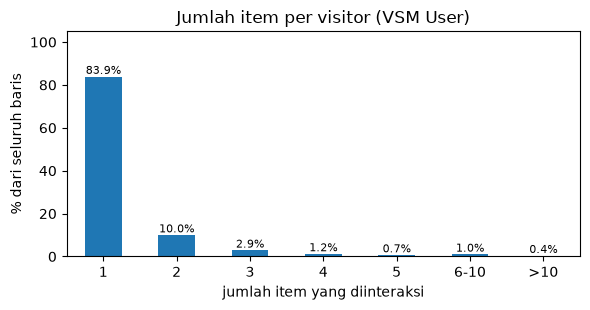

Sampel: 15 visitor, 10 item, 63 pasangan visitor-item


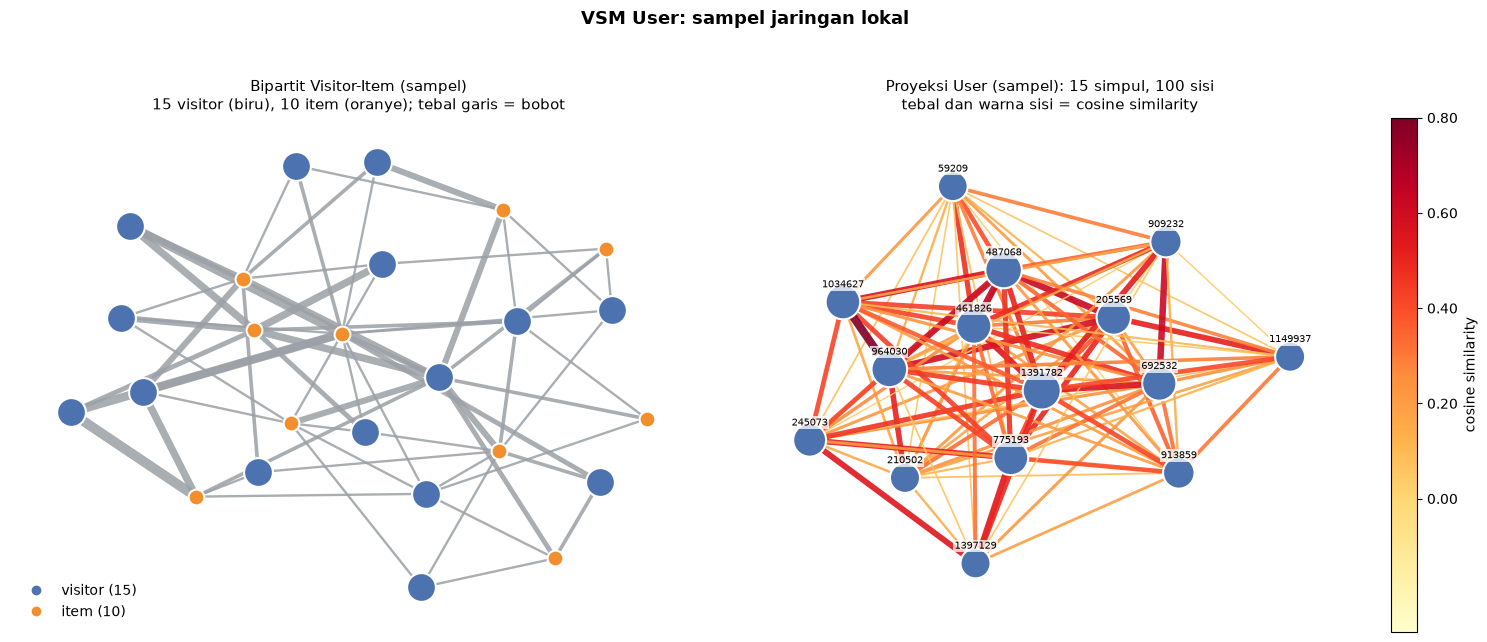

In [ ]:
import networkx as nx

pd.set_option("display.max_colwidth", None)

def idn(x, d=0):
    """Format angka gaya Indonesia: 1.234.567,8"""
    return f"{x:,.{d}f}".translate(str.maketrans(",.", ".,"))

def profil(M, nama):
    """Ringkasan karakteristik matriks VSM."""
    n_r, n_c = M.shape
    deg = np.diff(M.indptr)
    mem_sparse = (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6
    return pd.Series({
        "Shape (baris x kolom)": f"{idn(n_r)} x {idn(n_c)}",
        "Dimensi ruang vektor": idn(n_c),
        "Entri tidak nol (nnz)": idn(M.nnz),
        "Sparsity": f"{idn((1 - M.nnz / (n_r * n_c)) * 100, 4)}%",
        "Rata-rata entri per baris": idn(deg.mean(), 2),
        "Median / maks entri per baris": f"{idn(np.median(deg))} / {idn(deg.max())}",
        "Baris dengan 1 entri": f"{idn((deg == 1).mean() * 100, 1)}%",
        "Memori sparse": f"{idn(mem_sparse, 2)} MB",
        "Memori jika dense": f"{idn(n_r * n_c * 8 / 1e9, 1)} GB",
    }, name=nama)

def distribusi(deg):
    """Distribusi jumlah entri per baris (jumlah dan persen)."""
    kat = pd.cut(deg, bins=[0, 1, 2, 3, 4, 5, 10, np.inf], labels=["1", "2", "3", "4", "5", "6-10", ">10"])
    tab = pd.Series(kat).value_counts().sort_index().to_frame("jumlah")
    tab["persen"] = (tab["jumlah"] / tab["jumlah"].sum() * 100).round(1)
    return tab

def plot_distribusi(tab, judul, xlabel, warna):
    ax = tab["persen"].plot.bar(color=warna, figsize=(6, 3.2), rot=0)
    for p, v in zip(ax.patches, tab["persen"]):
        ax.annotate(f"{v:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(judul)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% dari seluruh baris")
    ax.set_ylim(0, 105)
    plt.tight_layout()
    plt.show()

def ambil_sampel(M, n_user=15, n_item=10, seed=42):
    """Sampel jaringan lokal: satu item pusat, item yang paling sering ikut disentuh oleh visitornya,
    lalu visitor yang menyentuh paling banyak item sampel (acak jika seri, seed tetap)."""
    rng = np.random.default_rng(seed)
    B = M.copy()
    B.data[:] = 1.0 # biner: ada / tidak ada interaksi
    deg_item = np.asarray(B.sum(axis=0)).ravel()
    pusat = int(rng.choice(np.where((deg_item >= 20) & (deg_item <= 100))[0]))

    vis_pusat = B[:, pusat].nonzero()[0] # visitor yang menyentuh item pusat
    ikut = np.asarray(B[vis_pusat].sum(axis=0)).ravel() # frekuensi item lain pada visitor tsb
    ikut[pusat] = -1
    id_item = np.r_[pusat, np.argsort(-ikut, kind="stable")[:n_item - 1]]

    jml = np.asarray(B[:, id_item].sum(axis=1)).ravel() # jumlah item sampel yang disentuh tiap visitor
    kand = np.where(jml >= 1)[0]
    urut = np.lexsort((rng.random(len(kand)), -jml[kand]))
    id_user = np.sort(kand[urut[:n_user]])
    return id_user, id_item

def hitung_cosine(S):
    """Cosine similarity antar baris sebuah matriks sparse kecil."""
    G = (S @ S.T).toarray()
    d = np.sqrt(np.diag(G))
    return G / np.outer(d, d)

def plot_sampel(sub, label_user, label_item, S, fokus, judul):
    """Kiri: graf bipartit sampel (tebal garis = bobot interaksi).
    Kanan: proyeksi sampel (tebal dan warna sisi = cosine similarity)."""
    biru, oranye, cmap = "#4C72B0", "#F28E2B", plt.cm.YlOrRd
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))

    # --- kiri: bipartit Visitor-Item
    G = nx.Graph()
    kecil, besar = 130, 430
    sub = sub.tocoo()
    for a, b, w in zip(sub.row, sub.col, sub.data):
        G.add_edge(f"U{label_user[a]}", f"I{label_item[b]}", bobot=w)
    nodes_u = [f"U{u}" for u in label_user if f"U{u}" in G]
    nodes_i = [f"I{i}" for i in label_item if f"I{i}" in G]
    pos = nx.spring_layout(G, k=0.8, seed=42, iterations=300)
    lebar = [0.8 + 0.9 * d["bobot"] for _, _, d in G.edges(data=True)]
    nx.draw_networkx_edges(G, pos, width=lebar, edge_color="#9aa0a6", alpha=0.85, ax=ax1)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_u, node_color=biru, edgecolors="white", linewidths=1.5,
                           node_size=besar if fokus == "user" else kecil, ax=ax1)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_i, node_color=oranye, edgecolors="white", linewidths=1.5,
                           node_size=besar if fokus == "item" else kecil, ax=ax1)
    ax1.plot([], [], "o", color=biru, label=f"visitor ({len(nodes_u)})")
    ax1.plot([], [], "o", color=oranye, label=f"item ({len(nodes_i)})")
    ax1.legend(loc="lower left", frameon=False)
    ax1.set_title(f"Bipartit Visitor-Item (sampel)\n{len(nodes_u)} visitor (biru), {len(nodes_i)} item (oranye); "
                  "tebal garis = bobot", fontsize=11)
    ax1.axis("off")

    # --- kanan: proyeksi
    ids = label_user if fokus == "user" else label_item
    warna = biru if fokus == "user" else oranye
    sim = hitung_cosine(S)
    P = nx.Graph()
    P.add_nodes_from(range(len(ids)))
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            if sim[a, b] > 0:
                P.add_edge(a, b, w=sim[a, b])
    pos2 = nx.spring_layout(P, weight="w", k=0.9, seed=42, iterations=300)
    w = np.array([d["w"] for _, _, d in P.edges(data=True)])
    kuat = np.array([sum(d["w"] for _, _, d in P.edges(n, data=True)) for n in P.nodes])
    ukuran = 250 + 500 * kuat / max(kuat.max(), 1e-9)
    wmax = w.max() if len(w) else 1.0
    if len(w):
        nx.draw_networkx_edges(P, pos2, width=0.8 + 5 * w / wmax, edge_color=w, edge_cmap=cmap,
                               edge_vmin=-0.35 * wmax, edge_vmax=wmax, alpha=0.9, ax=ax2)
    nx.draw_networkx_nodes(P, pos2, node_color=warna, node_size=ukuran, edgecolors="white", linewidths=1.5, ax=ax2)
    nx.draw_networkx_labels(P, {n: (x, y + 0.09) for n, (x, y) in pos2.items()},
                            labels={n: str(ids[n]) for n in P.nodes}, font_size=7.5,
                            bbox=dict(fc="white", ec="none", alpha=0.75, pad=0.8), ax=ax2)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-0.35 * wmax, wmax))
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax2, fraction=0.04, pad=0.02, label="cosine similarity")
    cb.set_ticks(np.linspace(0, wmax, 5))
    cb.set_ticklabels([f"{t:.2f}" for t in np.linspace(0, wmax, 5)])
    ax2.set_title(f"Proyeksi {'User' if fokus == 'user' else 'Item'} (sampel): {P.number_of_nodes()} simpul, "
                  f"{P.number_of_edges()} sisi\ntebal dan warna sisi = cosine similarity", fontsize=11)
    ax2.margins(0.12)
    ax2.axis("off")

    fig.suptitle(judul, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

display(profil(M_user, "VSM User (User x Item)").to_frame())

tab_user = distribusi(np.diff(M_user.indptr))
display(tab_user)
plot_distribusi(tab_user, "Jumlah item per visitor (VSM User)", "jumlah item yang diinteraksi", "tab:blue")

sampel_u, sampel_i = ambil_sampel(M_user)
sub_sampel = M_user[sampel_u][:, sampel_i]
print(f"Sampel: {len(sampel_u)} visitor, {len(sampel_i)} item, {sub_sampel.nnz} pasangan visitor-item")

plot_sampel(sub_sampel, visitors[sampel_u], items[sampel_i], M_user[sampel_u], "user",
            "VSM User: sampel jaringan lokal")


**Hasil: karakteristik VSM User (P1).**

| Karakteristik | Nilai |
|---|---|
| Shape (baris × kolom) | 153.836 × 76.078 |
| Dimensi matriks / ruang vektor | 2 / 76.078 (satu dimensi per item) |
| Entri tidak nol (nnz) | 213.066 |
| Sparsity | 99,9982% |
| Rata-rata entri per visitor | 1,39 |
| Median / maksimum entri per visitor | 1 / 910 |
| Visitor dengan 1 item | 83,9% |
| Memori sparse / dense | 3,17 MB / 93,6 GB |

Distribusi item per visitor: 1 item (83,9%), 2 (10,0%), 3 (2,9%), 4 (1,2%), 5 (0,7%), 6 sampai 10 (1,0%), dan lebih dari 10 (0,4%).

**Interpretasi.**
- Dari sekitar 11,7 miliar sel, hanya 213.066 yang terisi. Matriks sparse hanya memerlukan 3,17 MB, sedangkan bentuk dense memerlukan 93,6 GB.
- Nilai nnz (213.066) lebih kecil daripada jumlah relasi (265.509) karena beberapa event pada pasangan visitor-item yang sama dijumlahkan menjadi satu sel.
- Sebagian besar visitor hanya berinteraksi dengan satu item, sehingga vektor user sangat pendek dan jarang beririsan dengan user lain. Hal ini menyulitkan perbandingan antar user.
- Pada visualisasi, proyeksi User membentuk kelompok-kelompok visitor yang menyentuh item yang sama.

#### No. 5: VSM untuk simpul Item

> **Soal:** Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.).

**Konsep.** Ini adalah sisi sebaliknya dari no. 4. Setiap `Item` menjadi vektor di ruang `Visitor` (satu dimensi per visitor), sehingga matriksnya adalah **Item × User**, yaitu **transpose** dari matriks User × Item (`M_user.T`) dengan bobot sel yang sama.

Karakteristik yang sama ditampilkan (profil, distribusi, dan visualisasi). Visualisasi memakai **sampel yang sama** dengan no. 4, tetapi sekarang item yang ditonjolkan (simpul oranye besar) dan panel kanan menampilkan **proyeksi Item**: dua item terhubung bila dilihat oleh visitor yang sama.

,VSM Item (Item x User)
Shape (baris x kolom),76.078 x 153.836
Dimensi ruang vektor,153.836
Entri tidak nol (nnz),213.066
Sparsity,"99,9982%"
Rata-rata entri per baris,"2,80"
Median / maks entri per baris,1 / 1.317
Baris dengan 1 entri,"55,4%"
Memori sparse,"2,86 MB"
Memori jika dense,"93,6 GB"


,jumlah,persen
1,42123,55.4
2,13388,17.6
3,6587,8.7
4,3776,5.0
5,2492,3.3
6-10,4905,6.4
>10,2807,3.7


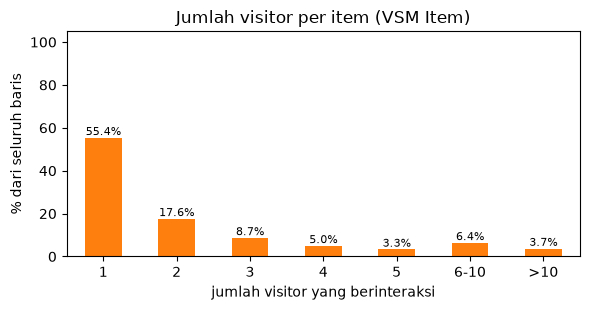

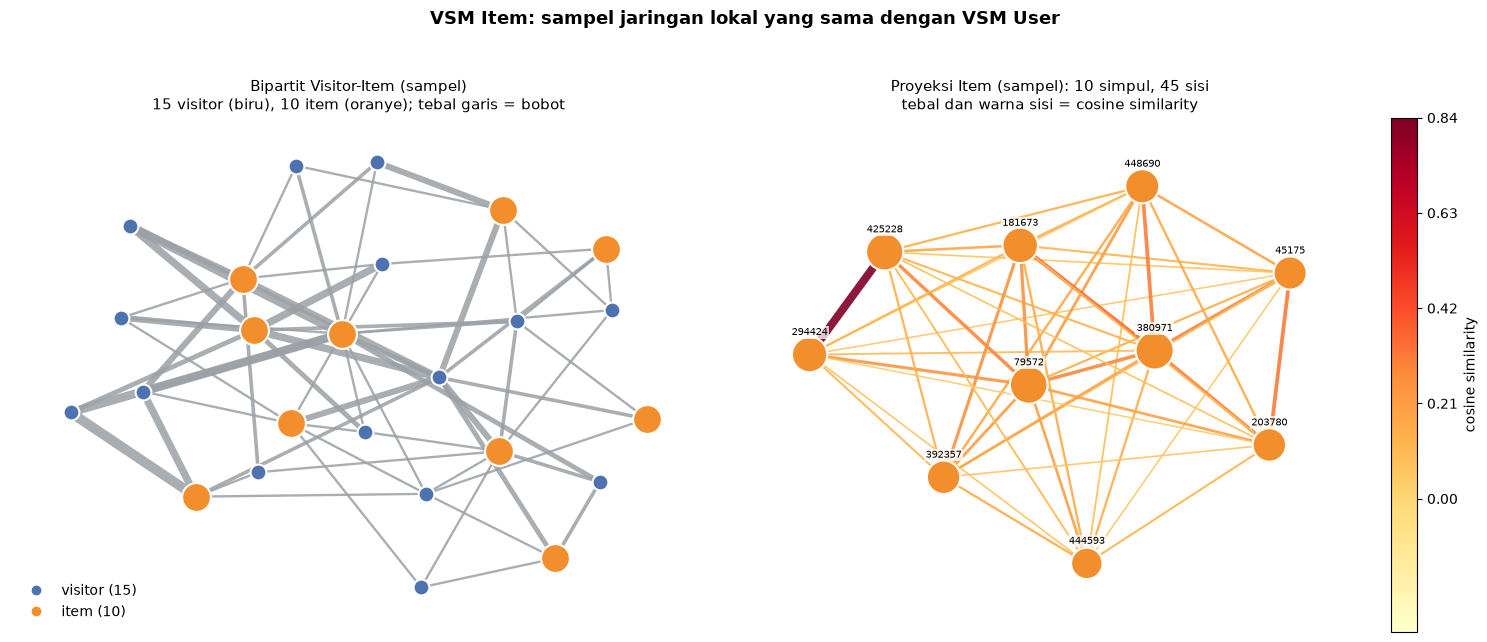

In [8]:
M_item = M_user.T.tocsr()

display(profil(M_item, "VSM Item (Item x User)").to_frame())

tab_item = distribusi(np.diff(M_item.indptr))
display(tab_item)
plot_distribusi(tab_item, "Jumlah visitor per item (VSM Item)", "jumlah visitor yang berinteraksi", "tab:orange")

plot_sampel(sub_sampel, visitors[sampel_u], items[sampel_i], M_item[sampel_i], "item",
            "VSM Item: sampel jaringan lokal yang sama dengan VSM User")


**Hasil: karakteristik VSM Item (P1).**

| Karakteristik | Nilai |
|---|---|
| Shape (baris × kolom) | 76.078 × 153.836 |
| Dimensi matriks / ruang vektor | 2 / 153.836 (satu dimensi per visitor) |
| Entri tidak nol (nnz) | 213.066 |
| Sparsity | 99,9982% |
| Rata-rata entri per item | 2,80 |
| Median / maksimum entri per item | 1 / 1.317 |
| Item dengan 1 visitor | 55,4% |
| Memori sparse / dense | 2,86 MB / 93,6 GB |

Distribusi visitor per item: 1 visitor (55,4%), 2 (17,6%), 3 (8,7%), 4 (5,0%), 5 (3,3%), 6 sampai 10 (6,4%), dan lebih dari 10 (3,7%).

**Interpretasi.**
- Jumlah entri tidak nol dan sparsity sama dengan matriks User, karena matriks ini hanyalah transpose-nya.
- Jumlah baris hanya sekitar separuh matriks User (76.078 dibanding 153.836), karena item lebih sedikit daripada visitor.
- Vektor item lebih "tebal": rata-rata 2,80 visitor per item (dibanding 1,39 item per visitor), dan hanya 55,4% item dengan satu visitor (dibanding 83,9% pada user).
- Distribusinya timpang (*long tail*): sedikit item sangat populer (hingga 1.317 visitor), sedangkan banyak item hanya disentuh satu visitor.

**Pola isi matriks (sparsity).** Sel berikut menggambar posisi sel yang terisi pada blok 300 visitor teraktif × 300 item terpopuler. Bagian terpadat dari matriks saja sudah terlihat sangat jarang, yang menunjukkan seberapa kosong matriks keseluruhan.

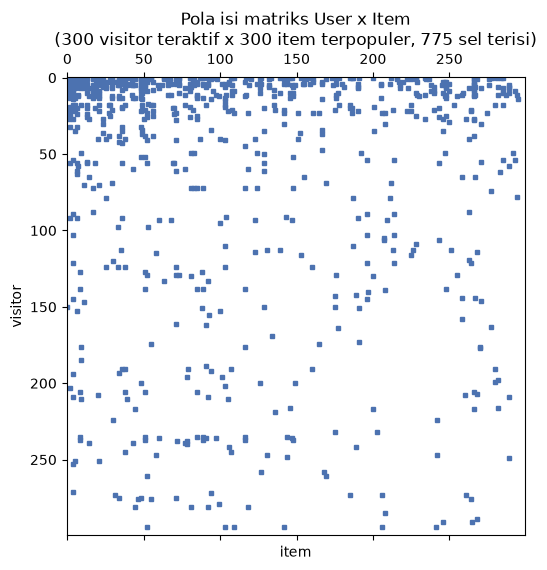

In [ ]:
top_u = np.argsort(-np.diff(M_user.indptr))[:300] # 300 visitor paling aktif
top_i = np.argsort(-np.diff(M_item.indptr))[:300] # 300 item paling populer
blok = M_user[top_u][:, top_i]

fig, ax = plt.subplots(figsize=(5.8, 5.8))
ax.spy(blok, markersize=2.5, color="#4C72B0")
ax.set_title(f"Pola isi matriks User x Item\n(300 visitor teraktif x 300 item terpopuler, {blok.nnz} sel terisi)")
ax.set_xlabel("item")
ax.set_ylabel("visitor")
plt.tight_layout()
plt.show()


#### No. 6: Memilih proyeksi yang lebih baik

> **Soal:** Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien).

**Konsep.** Graf bipartit dapat diproyeksikan menjadi dua graf:
- **User–User:** dua visitor terhubung bila berinteraksi dengan item yang sama. Matriks similarity berukuran visitor × visitor.
- **Item–Item:** dua item terhubung bila disentuh visitor yang sama. Matriks similarity berukuran item × item.

**Kriteria perbandingan.**

| Kriteria | Aspek | Cara menghitung |
|---|---|---|
| Ukuran matriks similarity | efisiensi | jumlah simpul n × n |
| Memori jika dense | efisiensi | n² × 8 byte |
| Estimasi pasangan yang dihitung | efisiensi | jumlah derajat kuadrat simpul perantara |
| Rata-rata entri per vektor dan persentase vektor dengan 1 entri | efektivitas | dari hasil no. 4 dan 5 |
| Waktu cosine untuk 100 baris pertama | efisiensi | waktu tercepat dari 3 kali ulang |

Estimasi pasangan: pada proyeksi User–User, perantaranya adalah item. Sebuah item yang disentuh *d* visitor menghasilkan sekitar *d²* pasangan visitor. Pada proyeksi Item–Item perantaranya adalah visitor, dengan cara hitung yang sama.

,User-User,Item-Item,Rasio Item/User
Metrik,,,
Jumlah simpul (matriks n x n),153.836,76.078,"0,49"
Memori similarity jika dense (GB),"189,3","46,3","0,24"
Estimasi pasangan yang dihitung,4.447.108,2.986.446,"0,67"
Rata-rata entri per vektor,"1,39","2,80","2,02"
Vektor dengan 1 entri (%),"83,9","55,4","0,66"
Waktu cosine 100 baris (detik),"0,042","0,022","0,54"


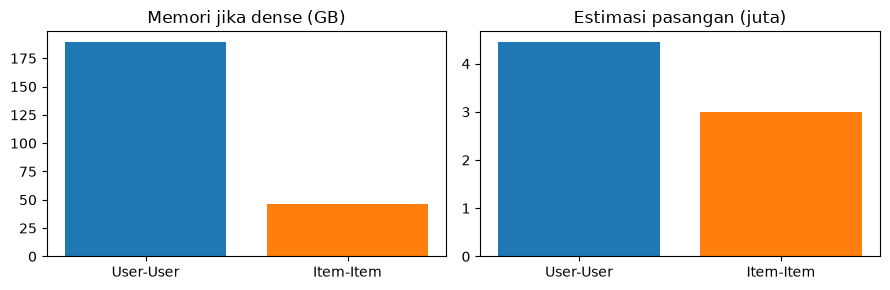

In [ ]:
import time
from sklearn.metrics.pairwise import cosine_similarity

n_u, n_i = M_user.shape
deg_user = np.diff(M_user.indptr).astype(np.int64) # item per visitor
deg_item = np.diff(M_item.indptr).astype(np.int64) # visitor per item

def waktu_cosine(M, n=100, ulang=3):
    hasil = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        cosine_similarity(M[:n], M)
        hasil.append(time.perf_counter() - t0)
    return min(hasil)

mem_uu, mem_ii = n_u**2 * 8 / 1e9, n_i**2 * 8 / 1e9
pas_uu, pas_ii = int((deg_item**2).sum()), int((deg_user**2).sum())

baris = [  # (metrik, User-User, Item-Item, jumlah desimal)
    ("Jumlah simpul (matriks n x n)", n_u, n_i, 0),
    ("Memori similarity jika dense (GB)", mem_uu, mem_ii, 1),
    ("Estimasi pasangan yang dihitung", pas_uu, pas_ii, 0),
    ("Rata-rata entri per vektor", deg_user.mean(), deg_item.mean(), 2),
    ("Vektor dengan 1 entri (%)", (deg_user == 1).mean() * 100, (deg_item == 1).mean() * 100, 1),
    ("Waktu cosine 100 baris (detik)", waktu_cosine(M_user), waktu_cosine(M_item), 3),
]
banding = pd.DataFrame(
    [{"Metrik": m, "User-User": idn(a, d), "Item-Item": idn(b, d), "Rasio Item/User": idn(b / a, 2)}
     for m, a, b, d in baris]
).set_index("Metrik")
display(banding)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(["User-User", "Item-Item"], [mem_uu, mem_ii], color=["tab:blue", "tab:orange"])
ax[0].set_title("Memori jika dense (GB)")
ax[1].bar(["User-User", "Item-Item"], [pas_uu / 1e6, pas_ii / 1e6], color=["tab:blue", "tab:orange"])
ax[1].set_title("Estimasi pasangan (juta)")
plt.tight_layout()
plt.show()


**Hasil perbandingan.**

| Metrik | User–User | Item–Item | Rasio Item/User |
|---|---:|---:|---:|
| Jumlah simpul (matriks n × n) | 153.836 | 76.078 | 0,49 |
| Memori similarity jika dense (GB) | 189,3 | 46,3 | 0,24 |
| Estimasi pasangan yang dihitung | 4.447.108 | 2.986.446 | 0,67 |
| Rata-rata entri per vektor | 1,39 | 2,80 | 2,02 |
| Vektor dengan 1 entri (%) | 83,9 | 55,4 | 0,66 |
| Waktu cosine 100 baris (detik) | 0,042 | 0,022 | 0,54 |

Diagram batang membandingkan kebutuhan memori dan estimasi jumlah pasangan kedua proyeksi. Waktu hitung dapat sedikit berbeda pada setiap eksekusi.

**Pola distribusi derajat.** Grafik berikut menampilkan distribusi derajat dalam skala log-log. Sumbu x adalah jumlah interaksi per simpul, sumbu y adalah jumlah simpul. Visitor (biru) terkonsentrasi pada derajat kecil, sedangkan item (oranye) memiliki ekor yang lebih panjang, yaitu lebih banyak item dengan derajat tinggi.

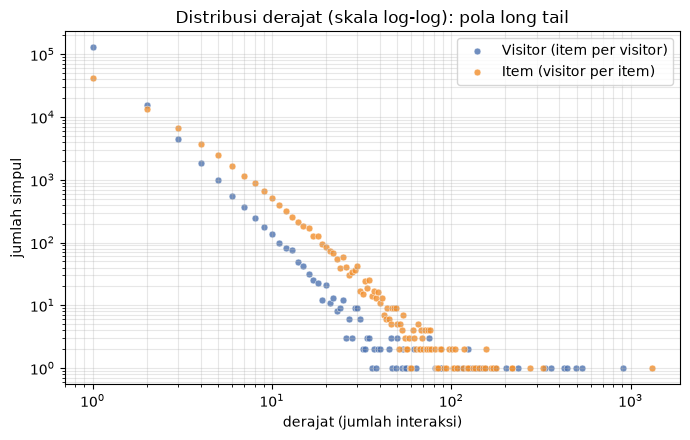

In [11]:
def frekuensi_derajat(deg):
    cacah = np.bincount(deg)[1:]
    x = np.arange(1, len(cacah) + 1)
    ada = cacah > 0
    return x[ada], cacah[ada]

fig, ax = plt.subplots(figsize=(7, 4.5))
for deg, nama, warna in [(deg_user, "Visitor (item per visitor)", "#4C72B0"),
                         (deg_item, "Item (visitor per item)", "#F28E2B")]:
    x, y = frekuensi_derajat(deg)
    ax.scatter(x, y, s=24, alpha=0.8, color=warna, label=nama, edgecolors="white", linewidths=0.4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("derajat (jumlah interaksi)")
ax.set_ylabel("jumlah simpul")
ax.set_title("Distribusi derajat (skala log-log): pola long tail")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()


**Kesimpulan no. 6: proyeksi Item–Item lebih baik**, baik dari sisi efisiensi maupun efektivitas.

*Efisien:*
- Matriks similarity hanya separuh ukurannya (76.078 × 76.078 dibanding 153.836 × 153.836), dengan memori dense sekitar seperempatnya (46,3 GB dibanding 189,3 GB).
- Jumlah pasangan yang dihitung lebih sedikit (2,99 juta dibanding 4,45 juta), dan waktu hitung lebih singkat (0,022 dibanding 0,042 detik, sekitar dua kali lebih cepat).

*Efektif:*
- Vektor item lebih "tebal" (rata-rata 2,80 entri, dibanding 1,39 pada vektor user). Hanya 55,4% item dengan satu visitor, sedangkan 83,9% visitor hanya memiliki satu item.
- Vektor user yang sangat pendek hampir tidak beririsan, sehingga similarity antar user kurang bermakna. Vektor item lebih sering beririsan, sehingga similarity lebih stabil.

Karena itu similarity (no. 7) dan KNN (bagian 2.2) dikerjakan pada proyeksi **Item–Item**.

#### No. 7: Menghitung similarity pada graf terproyeksi

> **Soal:** Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python. (a) Tuliskan Cypher untuk mendapatkan 5 records dengan similarity tertinggi (record acuannya ditentukan sendiri). (b) Tuliskan kembali nilai similarity tersebut pada graf yang telah ada dan perlihatkan hasil query-nya.

**Ukuran similarity: cosine biner.** Setiap item dipandang sebagai himpunan visitor yang berinteraksi dengannya di P1 (misalnya $V_a$ untuk item $a$), tanpa memperhatikan bobot (hanya ada atau tidak ada interaksi). Similarity item $a$ dan $b$ adalah:

$$\cos(a,b)=\frac{|V_a \cap V_b|}{\sqrt{|V_a|\cdot|V_b|}}$$

Pada kode: `shared` = $|V_a \cap V_b|$, `da` = $|V_a|$ (visitor item acuan), dan `db` = $|V_b|$ (visitor item pembanding). Nilainya berkisar dari 0 (tidak ada visitor yang sama) sampai 1 (himpunan visitor identik).

**Record acuan.** Dipilih satu item secara acak (seed 42) dari item yang memiliki 30 sampai 300 visitor di P1: cukup banyak agar punya tetangga, tetapi bukan item yang ekstrem. Seed tetap membuat pilihan dapat direproduksi.

**Langkah.**
1. Python menghitung similarity item acuan terhadap seluruh item dengan perkalian matriks sparse.
2. Cypher pada 7(a) menghitung nilai yang sama langsung di graf, lalu hasilnya dibandingkan.
3. Pada 7(b), nilainya ditulis kembali ke graf sebagai relasi.

In [ ]:
B_item = M_item.copy()
B_item.data[:] = 1.0

rng = np.random.default_rng(42)
kandidat = np.where((deg_item >= 30) & (deg_item <= 300))[0]
ref_idx = int(rng.choice(kandidat))
ref_item = int(items[ref_idx])
da = deg_item[ref_idx]
print("Item acuan:", ref_item, "| jumlah visitor di P1 (da):", da)

shared = (B_item @ B_item[ref_idx].T).toarray().ravel()   # |V_a ∩ V_b| untuk semua item
sims = shared / np.sqrt(da * deg_item) # cosine binerx
urut = np.lexsort((items, -sims))[:5]
top_py = pd.DataFrame({
    "itemId": items[urut].astype(int),
    "shared": shared[urut].astype(int),
    "db": deg_item[urut],
    "similarity": sims[urut],
})
display(top_py)


Item acuan: 45337 | jumlah visitor di P1 (da): 44


,itemId,shared,db,similarity
0,93467,1,1,0.150756
1,397515,1,1,0.150756
2,172773,1,2,0.106600
3,111433,1,5,0.067420
4,114695,1,7,0.056980


**Hasil perhitungan di Python.** Item acuan adalah **45337** dengan 44 visitor di P1. Lima item dengan similarity tertinggi:

| itemId | shared | db | similarity |
|---:|---:|---:|---:|
| 93467 | 1 | 1 | 0,1508 |
| 397515 | 1 | 1 | 0,1508 |
| 172773 | 1 | 2 | 0,1066 |
| 111433 | 1 | 5 | 0,0674 |
| 114695 | 1 | 7 | 0,0570 |

**No. 7(a): Cypher untuk 5 record dengan similarity tertinggi.** Query berikut menghitung cosine biner yang sama langsung di graf, hanya dari interaksi P1. Bagian-bagiannya:

| Potongan query | Penjelasan |
|---|---|
| `MATCH (a:Item {itemId: $ref})<-[r0]-(v:Visitor)` dengan filter `r0.timestamp` | visitor P1 yang berinteraksi dengan item acuan |
| `collect(DISTINCT v) AS vs`, `size(vs) AS da` | mengumpulkan visitor tersebut. Jumlahnya adalah `da` |
| `UNWIND vs AS v MATCH (v)-[r1]->(b:Item) WHERE b <> a` | item lain yang juga disentuh visitor tersebut (kandidat) |
| `count(DISTINCT v) AS shared` | jumlah visitor yang sama (irisan) |
| `MATCH (b)<-[r2]-(vb:Visitor)`, `count(DISTINCT vb) AS db` | seluruh visitor P1 milik item kandidat |
| `toFloat(shared) / sqrt(da * db)` | nilai cosine |
| `ORDER BY similarity DESC, itemId LIMIT 5` | lima tertinggi. Bila seri, `itemId` lebih kecil didahulukan agar hasil tetap |

Hasil Cypher dibandingkan dengan hasil Python. Keduanya harus identik.

In [13]:
query_top5 = """
MATCH (a:Item {itemId: $ref})<-[r0]-(v:Visitor)
WHERE r0.timestamp >= $ts AND r0.timestamp < $te
WITH a, collect(DISTINCT v) AS vs
WITH a, vs, size(vs) AS da
UNWIND vs AS v
MATCH (v)-[r1]->(b:Item)
WHERE b <> a AND r1.timestamp >= $ts AND r1.timestamp < $te
WITH a, da, b, count(DISTINCT v) AS shared
MATCH (b)<-[r2]-(vb:Visitor)
WHERE r2.timestamp >= $ts AND r2.timestamp < $te
WITH a, da, b, shared, count(DISTINCT vb) AS db
RETURN b.itemId AS itemId, shared, db,
       toFloat(shared) / sqrt(da * db) AS similarity
ORDER BY similarity DESC, itemId
LIMIT 5
"""

with driver.session() as session:
    top_cy = pd.DataFrame(session.run(query_top5, ref=ref_item, **p1).data())
display(top_cy)

sama = list(top_py["itemId"]) == list(top_cy["itemId"]) and np.allclose(top_py["similarity"], top_cy["similarity"])
print("Hasil Python sama dengan hasil Cypher:", sama)


,itemId,shared,db,similarity
0,93467,1,1,0.150756
1,397515,1,1,0.150756
2,172773,1,2,0.106600
3,111433,1,5,0.067420
4,114695,1,7,0.056980


Hasil Python sama dengan hasil Cypher: True


**Hasil.** Keluaran Cypher identik dengan hasil Python (tabel yang sama), dan perbandingan otomatis menampilkan `True`.

**Interpretasi.**
- Kelima item hanya berbagi **satu** visitor dengan item acuan (`shared = 1`).
- Skor tertinggi 0,1508 berasal dari 1 / √(44 × 1). Item dengan sedikit visitor (`db` kecil) mendapat skor tinggi karena penyebut yang kecil. Ini sifat cosine pada data yang sangat jarang.
- Karena datanya jarang, kualitas rekomendasi dinilai dengan evaluasi Hit@5 dan NDCG@5 pada bagian 2.2.

Diagram batang berikut menampilkan kelima item beserta nilai `shared` dan `db`-nya.

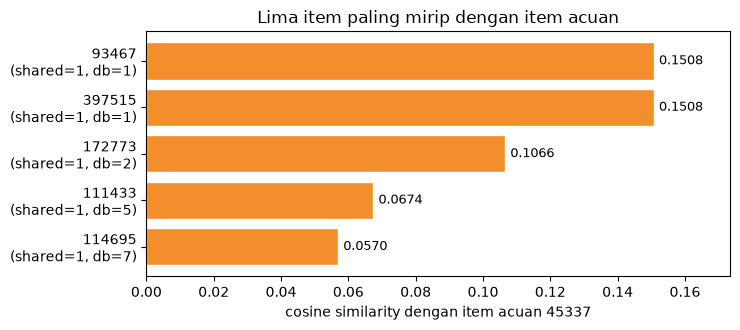

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
label = [f"{i}\n(shared={s}, db={d})" for i, s, d in zip(top_cy["itemId"], top_cy["shared"], top_cy["db"])]
nilai = top_cy["similarity"].to_numpy()
ax.barh(label[::-1], nilai[::-1], color="#F28E2B", edgecolor="white")
for y_, v in enumerate(nilai[::-1]):
    ax.text(v + nilai.max() * 0.01, y_, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0, nilai.max() * 1.15)
ax.set_xlabel(f"cosine similarity dengan item acuan {ref_item}")
ax.set_title("Lima item paling mirip dengan item acuan")
plt.tight_layout()
plt.show()


**Kondisi sebelum similarity (persiapan No. 8).** Sebelum nilai similarity ditulis ke graf, sel berikut mencatat kondisi awal yang akan dibandingkan pada No. 8:
- jumlah relasi per tipe di seluruh graf;
- visitor P1 yang menghubungkan item acuan dengan item-item mirip (untuk digambar).

Relasi `SIMILAR_TO` lama (jika ada) dihapus terlebih dahulu agar kondisi "sebelum" selalu bersih ketika notebook dijalankan ulang.

In [15]:
top_items = [int(x) for x in top_cy["itemId"]]

q_sub = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE (i.itemId = $ref OR i.itemId IN $items) AND r.timestamp >= $ts AND r.timestamp < $te
WITH v, collect(DISTINCT i.itemId) AS tersentuh
WHERE $ref IN tersentuh AND size(tersentuh) >= 2
RETURN v.visitorId AS visitor, tersentuh
ORDER BY size(tersentuh) DESC, visitor
LIMIT 8
"""

with driver.session() as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s")
    sebelum = pd.DataFrame(session.run(q_full_relasi).data()).set_index("jenis")["jumlah"]
    sub_vi = session.run(q_sub, ref=ref_item, items=top_items, **p1).data()

print("SEBELUM similarity: relasi per tipe")
display(sebelum.to_frame("jumlah"))


SEBELUM similarity: relasi per tipe


,jumlah
jenis,
VIEWED,2664312
ADDED_TO_CART,69332
BOUGHT,22457


**Hasil.** Sebelum perhitungan similarity, graf hanya memiliki tiga tipe relasi: `VIEWED` (2.664.312), `ADDED_TO_CART` (69.332), dan `BOUGHT` (22.457).

**No. 7(b): Menulis kembali nilai similarity ke graf.** Lima nilai dari 7(a) disimpan sebagai relasi baru dari item acuan ke tiap item mirip:

`(:Item {acuan})-[:SIMILAR_TO {score}]->(:Item {mirip})`

- `UNWIND $rows AS row` mengulang untuk tiap pasangan dari kelima hasil.
- `MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.itemId})` menemukan simpul acuan dan simpul mirip.
- `MERGE (a)-[s:SIMILAR_TO]->(b)` membuat relasi (tidak ganda bila sel dijalankan ulang), kemudian `SET s.score = row.similarity` menyimpan nilainya.
- Query kedua membaca kembali relasi yang tersimpan untuk membuktikan penulisan berhasil.

In [16]:
q_tulis = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.itemId})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.similarity
"""
q_baca = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS score
ORDER BY score DESC, mirip
"""
rows_sim = [{"itemId": int(i), "similarity": float(s)} for i, s in zip(top_cy["itemId"], top_cy["similarity"])]

with driver.session() as session:
    session.run(q_tulis, rows=rows_sim, ref=ref_item)
    hasil_graf = pd.DataFrame(session.run(q_baca, ref=ref_item).data())
display(hasil_graf)


,acuan,mirip,score
0,45337,93467,0.150756
1,45337,397515,0.150756
2,45337,172773,0.106600
3,45337,111433,0.067420
4,45337,114695,0.056980


**Hasil.** Lima relasi `SIMILAR_TO` dari item 45337 tersimpan di graf beserta `score`-nya, identik dengan hasil 7(a). Relasi ini membuat proyeksi Item–Item dapat dibaca langsung lewat query Cypher.

#### No. 8: Kondisi sebelum dan sesudah perhitungan similarity

> **Soal:** Tuliskan Cypher dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi sebelum dan sesudah perhitungan similarity.

**Cypher untuk Neo4j Browser** (hasilnya dapat di-*screenshot*):

```cypher
// SEBELUM: interaksi visitor dengan item acuan dan 5 item mirip (periode P1)
MATCH (v:Visitor)-[r]->(i:Item)
WHERE i.itemId IN [45337, 93467, 397515, 172773, 111433, 114695]
  AND r.timestamp >= 1438387200000 AND r.timestamp < 1439683200000
RETURN v, r, i LIMIT 50;

// SESUDAH: relasi SIMILAR_TO dari item acuan
MATCH p = (a:Item {itemId: 45337})-[:SIMILAR_TO]->(b:Item)
RETURN p;
```

**Visualisasi pada sel berikut** (networkx, tata letak berbasis gaya sehingga simpul yang terhubung berdekatan):
- Simpul **hijau** adalah item acuan, **biru** adalah visitor P1 yang menghubungkan item, dan **oranye** adalah item mirip.
- Garis abu-abu adalah interaksi `Visitor → Item`, sedangkan garis **merah putus-putus** adalah relasi `SIMILAR_TO`. Pada panel sesudah, ukuran simpul oranye sebanding dengan nilai similarity.
- Posisi simpul sengaja dibuat sama pada kedua panel agar perbedaannya mudah dibandingkan.

Jumlah relasi per tipe, sebelum dan sesudah similarity


,Sebelum,Sesudah
jenis,,
ADDED_TO_CART,69332,69332
BOUGHT,22457,22457
SIMILAR_TO,0,5
VIEWED,2664312,2664312


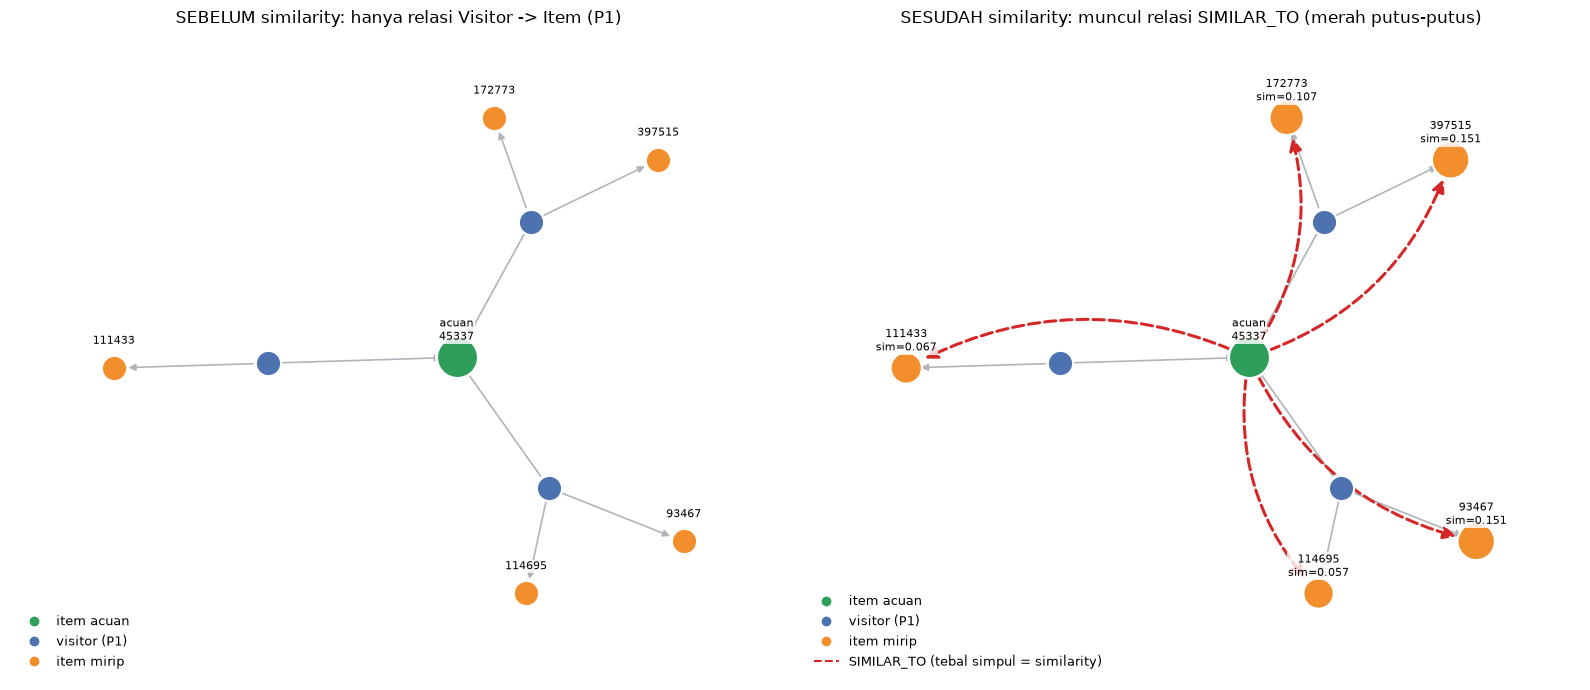

In [ ]:
with driver.session() as session:
    sesudah = pd.DataFrame(session.run(q_full_relasi).data()).set_index("jenis")["jumlah"]
    sim_db = pd.DataFrame(session.run(q_baca, ref=ref_item).data())

print("Jumlah relasi per tipe, sebelum dan sesudah similarity")
display(pd.DataFrame({"Sebelum": sebelum, "Sesudah": sesudah}).fillna(0).astype(int))

def gambar_sebelum_sesudah(ref, top, sub_vi, sim_db):
    skor = dict(zip(sim_db["mirip"], sim_db["score"]))
    top = sorted(top, key=lambda t: -skor[t]) # urut dari similarity tertinggi

    vi_edges = [(f"V{r['visitor']}", f"I{t}") for r in sub_vi for t in r["tersentuh"]]
    D = nx.DiGraph(vi_edges)
    D.add_node(f"I{ref}")
    D.add_nodes_from(f"I{t}" for t in top)
    pos = nx.spring_layout(D.to_undirected(), k=0.9, seed=42, iterations=300) # layout sama di kedua panel
    visitors_ = [n for n in D.nodes if n.startswith("V")]
    items_ = [f"I{t}" for t in top]
    sim_edges = [(f"I{ref}", f"I{t}") for t in top]

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, sesudah_ in zip(axes, [False, True]):
        nx.draw_networkx_edges(D, pos, edgelist=vi_edges, edge_color="#b0b4ba", width=1.2, arrows=True,
                               arrowsize=10, node_size=450, ax=ax)
        nx.draw_networkx_nodes(D, pos, nodelist=visitors_, node_color="#4C72B0", node_size=330,
                               edgecolors="white", linewidths=1.5, ax=ax)
        ukuran = [330 + 2600 * skor[t] for t in top] if sesudah_ else 330
        nx.draw_networkx_nodes(D, pos, nodelist=items_, node_color="#F28E2B", node_size=ukuran,
                               edgecolors="white", linewidths=1.5, ax=ax)
        nx.draw_networkx_nodes(D, pos, nodelist=[f"I{ref}"], node_color="#2E9E5B", node_size=900,
                               edgecolors="white", linewidths=2, ax=ax)

        label = {f"I{ref}": f"acuan\n{ref}"}
        label.update({f"I{t}": (f"{t}\nsim={skor[t]:.3f}" if sesudah_ else str(t)) for t in top})
        nx.draw_networkx_labels(D, {n: (x, y + 0.11) for n, (x, y) in pos.items()}, labels=label, font_size=8,
                                bbox=dict(fc="white", ec="none", alpha=0.8, pad=0.6), ax=ax)

        if sesudah_:
            H = nx.DiGraph(sim_edges)
            nx.draw_networkx_edges(H, pos, edge_color="#D62728", style="dashed", width=2.2, arrows=True,
                                   arrowsize=18, node_size=900, connectionstyle="arc3,rad=0.25", ax=ax)
        ax.plot([], [], "o", color="#2E9E5B", label="item acuan")
        ax.plot([], [], "o", color="#4C72B0", label="visitor (P1)")
        ax.plot([], [], "o", color="#F28E2B", label="item mirip")
        if sesudah_:
            ax.plot([], [], "--", color="#D62728", label="SIMILAR_TO (tebal simpul = similarity)")
        ax.legend(loc="lower left", frameon=False, fontsize=9)
        ax.set_title("SESUDAH similarity: muncul relasi SIMILAR_TO (merah putus-putus)" if sesudah_
                     else "SEBELUM similarity: hanya relasi Visitor -> Item (P1)", fontsize=12)
        ax.margins(0.12)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

gambar_sebelum_sesudah(ref_item, top_items, sub_vi, sim_db)


**Hasil.** Jumlah relasi per tipe sebelum dan sesudah similarity:

| Tipe relasi | Sebelum | Sesudah |
|---|---:|---:|
| `ADDED_TO_CART` | 69.332 | 69.332 |
| `BOUGHT` | 22.457 | 22.457 |
| `SIMILAR_TO` | 0 | 5 |
| `VIEWED` | 2.664.312 | 2.664.312 |

**Interpretasi.**
- Relasi interaksi tidak berubah. Perhitungan similarity hanya **menambahkan** 5 relasi `SIMILAR_TO`.
- Sebelum similarity, item acuan hanya terhubung ke item lain secara **tidak langsung**, lewat visitor yang berinteraksi dengan keduanya.
- Sesudah similarity, item acuan terhubung **langsung** ke lima item paling mirip, dan kedekatannya tersimpan sebagai `score`.

### 2.2 Analytics

**Hubungan dengan No. 7.** Pada 2.1 no. 7, similarity item–item didemonstrasikan pada satu item acuan (45337), sesuai soal ("record acuannya Anda tentukan sendiri"). Pada 2.2, similarity yang sama (cosine biner pada proyeksi Item–Item) dipakai untuk merekomendasikan item kepada satu **user acak**. Karena itu item yang dibahas di sini berasal dari riwayat user tersebut, bukan dari item acuan pada no. 7.

#### No. 1: Memilih user acak dan merekomendasikan item dengan KNN

> **Soal:** Pilih seorang user secara acak (tentukan proses acaknya, dan harus bisa direproduksi), lalu (a) tuliskan skrip Python dalam merekomendasikan KNN-nya, dan (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN-nya.

**Pemilihan user (acak dan dapat direproduksi).** `np.random.default_rng(42)` memilih satu user dari kandidat yang memenuhi tiga syarat:

| Syarat | Alasan |
|---|---|
| Ada di P1 dan P2 | punya riwayat untuk dasar rekomendasi dan punya kunci jawaban untuk evaluasi |
| Memiliki 2 sampai 30 item di P1 | cukup bahan bagi KNN, tetapi tidak terlalu berat dihitung |
| Memiliki minimal satu item di P2 yang belum pernah dilihat di P1 dan ada di graf P1 | item yang tidak ada di P1 tidak mungkin direkomendasikan oleh KNN berbasis item |

Seed yang tetap membuat user terpilih selalu sama.

In [18]:
def item_terlihat(u):
    """Item yang diinteraksi user u di P1."""
    r = v_idx.loc[u]
    return set(int(x) for x in items[M_user.indices[M_user.indptr[r]:M_user.indptr[r + 1]]])

test_f = test[test["itemid"].isin(i_idx.index) & test["visitorid"].isin(v_idx.index)]
truth = test_f.groupby("visitorid")["itemid"].apply(set)
n_seen = pd.Series(np.diff(M_user.indptr), index=visitors)

def truth_baru(u):
    """Ground truth: item P2 yang belum dilihat user di P1."""
    return {int(x) for x in truth.loc[u]} - item_terlihat(u)

eligible = np.sort(np.array([
    int(u) for u in truth.index if 2 <= n_seen.loc[u] <= 30 and len(truth_baru(u)) > 0
]))

rng = np.random.default_rng(42)
user_id = int(rng.choice(eligible))
seen_items = item_terlihat(user_id)
truth_user = truth_baru(user_id)

print("Jumlah kandidat user:", len(eligible))
print("User terpilih:", user_id)
print("Ground truth (item baru di P2):", sorted(truth_user))

r_ = v_idx.loc[user_id]
riwayat = pd.DataFrame({
    "itemId": items[M_user.indices[M_user.indptr[r_]:M_user.indptr[r_ + 1]]].astype(int),
    "bobot di P1": M_user.data[M_user.indptr[r_]:M_user.indptr[r_ + 1]].astype(int),
})
print("Riwayat interaksi user di P1:")
display(riwayat)


Jumlah kandidat user: 792
User terpilih: 123595
Ground truth (item baru di P2): [184620, 462070]
Riwayat interaksi user di P1:


,itemId,bobot di P1
0,20623,1
1,96680,2
2,101196,2
3,111831,1
4,134436,1
5,144513,3
6,148730,1
7,184217,2
8,190304,4
9,263258,4


**Hasil.** Terdapat **792 kandidat user**. Dengan seed 42 terpilih **user 123595**.
- **Riwayat P1:** 16 item. Dua item dengan bobot tertinggi (4) adalah 190304 dan 263258.
- **Ground truth:** dua item baru yang diinteraksi user di P2, yaitu **184620** dan **462070**.

**Skrip KNN (jawaban 1a): KNN berbasis item.** Mengikuti proyeksi Item–Item (no. 6), rekomendasi dibuat dari kemiripan antar item dengan $k = 5$ tetangga. Langkah untuk satu user:

1. **Riwayat user:** ambil item yang diinteraksi user di P1 beserta bobotnya ($w_i$).
2. **Tetangga:** untuk tiap item riwayat $i$, hitung cosine biner terhadap seluruh item (sama seperti no. 7), keluarkan item yang sudah pernah dilihat user, lalu ambil $k = 5$ item tetangga terdekat.
3. **Skor kandidat:** setiap tetangga $j$ mengumpulkan skor dari semua item riwayat yang menunjuknya:

$$\text{skor}(j)=\sum_{i}\; w_i \cdot \text{sim}(i,j)$$

4. **Urutkan:** skor menurun. Bila skor sama, `itemId` yang lebih kecil didahulukan agar hasilnya tetap.

Item dengan bobot interaksi lebih besar (misalnya pembelian) dan tetangga yang lebih mirip menyumbang skor lebih tinggi.

In [ ]:
def rekomendasi_knn(user_id, k=5, top_n=5):
    r = v_idx.loc[user_id]
    s, e = M_user.indptr[r], M_user.indptr[r + 1]
    seen_cols = M_user.indices[s:e] # item yang diinteraksi user
    seen_w = M_user.data[s:e] # bobot interaksi

    sim = cosine_similarity(B_item[seen_cols], B_item) # (n_seen x n_item)
    sim[:, seen_cols] = 0  # jangan rekomendasikan yang sudah dilihat

    skor = np.zeros(len(items))
    detail = []
    for a, (c, w) in enumerate(zip(seen_cols, seen_w)):
        tetangga = np.argsort(-sim[a], kind="stable")[:k] # k tetangga terdekat
        for j in tetangga:
            if sim[a, j] > 0:
                skor[j] += w * sim[a, j]
                detail.append((int(items[c]), int(items[j]), float(sim[a, j]), float(w)))

    urut = np.lexsort((items, -skor))
    urut = [j for j in urut if skor[j] > 0][:top_n]
    rec = pd.DataFrame({"rank": range(1, len(urut) + 1),
                        "itemId": items[urut].astype(int),
                        "skor": skor[urut]})
    det = pd.DataFrame(detail, columns=["item_dilihat", "tetangga", "similarity", "bobot"])
    return rec, det

rec, det = rekomendasi_knn(user_id, k=5, top_n=5)

# tetangga terdekat (k = 5) dari tiap item yang dilihat user
tetangga_per_item = (
    det.assign(txt=det["tetangga"].astype(str) + " (" + det["similarity"].round(2).astype(str) + ")")
       .groupby("item_dilihat")["txt"].agg(", ".join).to_frame("tetangga terdekat (similarity)")
)
print("Tetangga terdekat tiap item yang dilihat user:")
display(tetangga_per_item)

# asal skor tiap rekomendasi
def asal(item):
    d = det[det["tetangga"] == item]
    return "; ".join(f"{a} (sim {s:.2f} x bobot {w:.0f})"
                     for a, s, w in zip(d["item_dilihat"], d["similarity"], d["bobot"]))

rec["asal skor: item dilihat (sim x bobot)"] = rec["itemId"].map(asal)
print("Top-5 rekomendasi:")
display(rec)


Tetangga terdekat tiap item yang dilihat user:


,tetangga terdekat (similarity)
item_dilihat,
20623,265780 (0.35)
96680,"113754 (0.21), 132335 (0.21), 158088 (0.21), 437900 (0.21), 456986 (0.21)"
101196,"113754 (0.71), 132335 (0.71), 160268 (0.5), 348361 (0.32)"
134436,265780 (0.29)
144513,"168546 (0.5), 184657 (0.5), 266566 (0.5), 280339 (0.5), 281676 (0.5)"
148730,"168546 (0.5), 184657 (0.5), 266566 (0.5), 280339 (0.5), 281676 (0.5)"
184217,"26416 (0.23), 113754 (0.23), 132335 (0.23), 276537 (0.23), 446915 (0.23)"
190304,426566 (0.16)
263258,"146163 (0.16), 296901 (0.16), 329133 (0.16), 352559 (0.16), 10935 (0.14)"


Top-5 rekomendasi:


,rank,itemId,skor,asal skor: item dilihat (sim x bobot)
0,1,113754,2.600958,96680 (sim 0.21 x bobot 2); 101196 (sim 0.71 x bobot 2); 184217 (sim 0.23 x bobot 2); 425186 (sim 0.15 x bobot 2)
1,2,132335,2.600958,96680 (sim 0.21 x bobot 2); 101196 (sim 0.71 x bobot 2); 184217 (sim 0.23 x bobot 2); 425186 (sim 0.15 x bobot 2)
2,3,168546,2.000000,144513 (sim 0.50 x bobot 3); 148730 (sim 0.50 x bobot 1)
3,4,184657,2.000000,144513 (sim 0.50 x bobot 3); 148730 (sim 0.50 x bobot 1)
4,5,266566,2.000000,144513 (sim 0.50 x bobot 3); 148730 (sim 0.50 x bobot 1)


**Cara membaca keluaran.** Tabel pertama memuat tetangga terdekat dari tiap item riwayat beserta similarity-nya. Tabel kedua memuat lima rekomendasi teratas beserta asal skornya, yaitu item riwayat yang menunjuknya.

**Hasil.**

| Rank | itemId | Skor | Asal skor (item riwayat, similarity × bobot) |
|---:|---:|---:|---|
| 1 | 113754 | 2,6010 | 96680 (0,21 × 2), 101196 (0,71 × 2), 184217 (0,23 × 2), 425186 (0,15 × 2) |
| 2 | 132335 | 2,6010 | sama dengan rank 1 |
| 3 | 168546 | 2,0000 | 144513 (0,50 × 3), 148730 (0,50 × 1) |
| 4 | 184657 | 2,0000 | sama dengan rank 3 |
| 5 | 266566 | 2,0000 | sama dengan rank 3 |

Item 113754 dan 132335 unggul karena menjadi tetangga dari **empat** item riwayat sekaligus, sehingga skornya terakumulasi. Item 168546, 184657, dan 266566 memperoleh skor yang sama persis dari dua item riwayat yang sama (1,5 + 0,5), sehingga urutannya ditentukan oleh `itemId`.

**No. 1(b): Tiga item yang diiklankan (k = 5).** Tiga item teratas dari ranking KNN dipilih sebagai item yang diiklankan. Lima teratas dipakai untuk evaluasi Hit@5 dan NDCG@5. Bila skor sama, `itemId` yang lebih kecil didahulukan (tie-break tetap, sehingga hasil dapat direproduksi).

In [20]:
iklan = rec.head(3)[["rank", "itemId", "skor"]]
display(iklan)
print("3 item yang diiklankan untuk user", user_id, ":", list(iklan["itemId"]))


,rank,itemId,skor
0,1,113754,2.600958
1,2,132335,2.600958
2,3,168546,2.000000


3 item yang diiklankan untuk user 123595 : [113754, 132335, 168546]


**Hasil.** Tiga item yang diiklankan untuk user 123595 adalah **113754** (skor 2,6010), **132335** (2,6010), dan **168546** (2,0000).

**Visualisasi proses rekomendasi.** Graf berikut menjelaskan bagaimana rekomendasi terbentuk untuk user terpilih. Tata letak berbasis gaya, sehingga simpul yang saling terhubung berdekatan:
- **Ungu:** user terpilih.
- **Biru:** item riwayat P1. Ukuran simpul menunjukkan bobot interaksi.
- **Oranye:** lima item rekomendasi dengan label peringkat (`#1` sampai `#5`). Garis dari item riwayat ke rekomendasi menunjukkan asal skor, dan makin tebal serta merah berarti makin besar nilai bobot × similarity.
- **Hijau (putus-putus):** ground truth, yaitu item yang benar-benar diinteraksi user di P2. Jika sebuah rekomendasi cocok dengan ground truth, simpulnya diberi lingkaran hijau (*hit*). Ground truth yang tidak masuk lima rekomendasi digambar sebagai belah ketupat hijau berlabel `GT`.

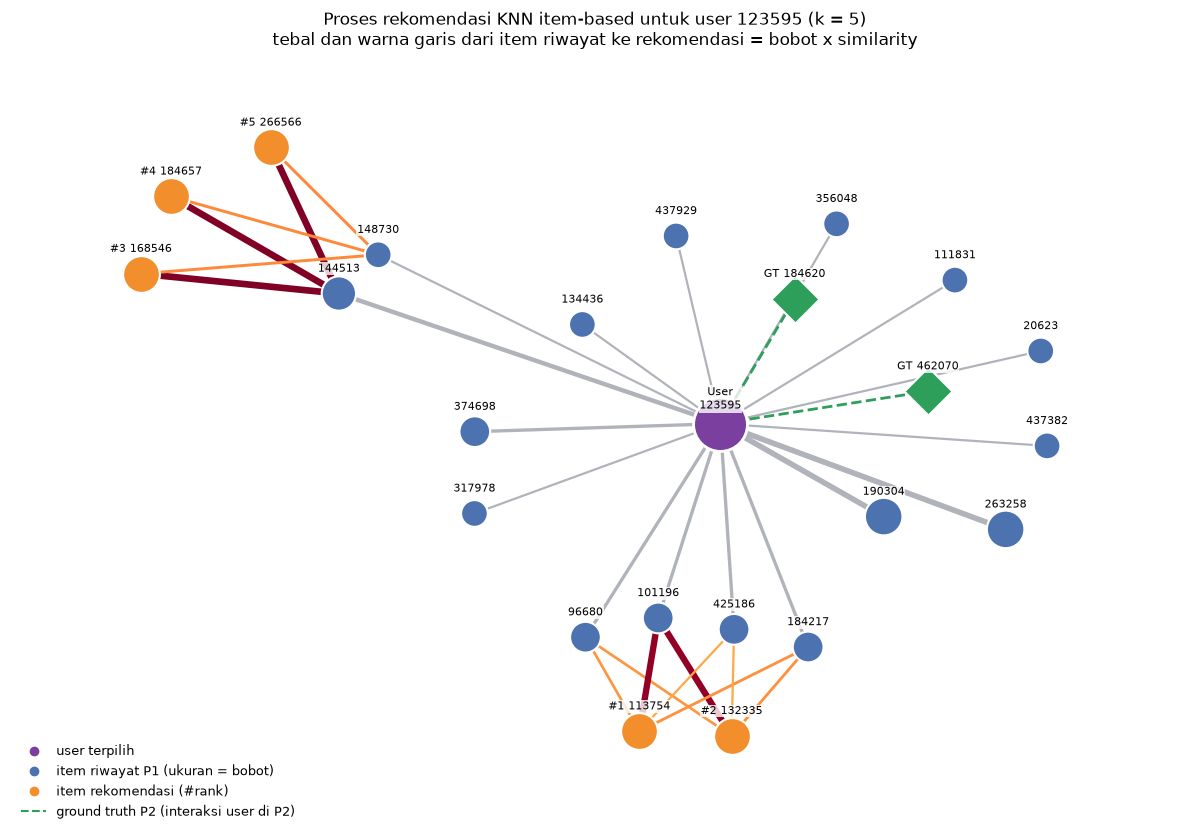

In [ ]:
def gambar_rekomendasi(user_id, riwayat, det, rec, truth_user, top_n=5):
    rec_top = rec.head(top_n)
    rec_ids = list(rec_top["itemId"])
    bobot = dict(zip(riwayat["itemId"], riwayat["bobot di P1"]))
    d = det[det["tetangga"].isin(rec_ids)]

    U = f"User {user_id}"
    G = nx.Graph()
    G.add_node(U)
    for it, w in bobot.items():
        G.add_edge(U, f"H{it}", w=w)
    for _, r in d.iterrows():
        G.add_edge(f"H{int(r['item_dilihat'])}", f"N{int(r['tetangga'])}", w=r["similarity"] * r["bobot"])
    for t in truth_user:
        G.add_edge(U, f"N{t}", w=1.0)
    pos = nx.spring_layout(G, k=0.9, seed=42, iterations=300)

    hist = [f"H{it}" for it in bobot]
    rec_nodes = [f"N{i}" for i in rec_ids]
    truth_nodes = [f"N{t}" for t in truth_user]
    kena = [n for n in rec_nodes if n in truth_nodes] # rekomendasi yang tepat (hit)
    hanya_truth = [n for n in truth_nodes if n not in rec_nodes]

    fig, ax = plt.subplots(figsize=(12, 8.5))
    e_user = [(U, h) for h in hist]
    e_rec = [(h, n) for h, n in G.edges if h.startswith("H") and n.startswith("N")]
    e_truth = [(U, n) for n in truth_nodes]
    nx.draw_networkx_edges(G, pos, edgelist=e_user, width=[0.8 + 0.8 * G[a][b]["w"] for a, b in e_user],
                           edge_color="#b0b4ba", ax=ax)
    w_rec = np.array([G[a][b]["w"] for a, b in e_rec])
    if len(e_rec):
        nx.draw_networkx_edges(G, pos, edgelist=e_rec, width=0.8 + 4 * w_rec / w_rec.max(), edge_color=w_rec,
                               edge_cmap=plt.cm.YlOrRd, edge_vmin=-0.35 * w_rec.max(), edge_vmax=w_rec.max(), ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=e_truth, edge_color="#2E9E5B", style="dashed", width=2, ax=ax)

    nx.draw_networkx_nodes(G, pos, nodelist=hist, node_color="#4C72B0", node_size=[250 + 120 * bobot[int(h[1:])] for h in hist],
                           edgecolors="white", linewidths=1.5, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=rec_nodes, node_color="#F28E2B", node_size=700, edgecolors="white",
                           linewidths=1.5, ax=ax)
    if kena:
        nx.draw_networkx_nodes(G, pos, nodelist=kena, node_color="none", node_size=1100, edgecolors="#2E9E5B",
                               linewidths=3.5, ax=ax)
    if hanya_truth:
        nx.draw_networkx_nodes(G, pos, nodelist=hanya_truth, node_color="#2E9E5B", node_shape="D", node_size=600,
                               edgecolors="white", linewidths=1.5, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[U], node_color="#7B3FA0", node_size=1500, edgecolors="white",
                           linewidths=2, ax=ax)

    label = {U: f"User\n{user_id}"}
    label.update({h: h[1:] for h in hist})
    label.update({f"N{i}": f"#{k} {i}" for k, i in enumerate(rec_ids, start=1)})
    label.update({n: f"GT {n[1:]}" for n in hanya_truth})
    nx.draw_networkx_labels(G, {n: (x, y + 0.075) for n, (x, y) in pos.items()}, labels=label, font_size=8,
                            bbox=dict(fc="white", ec="none", alpha=0.8, pad=0.6), ax=ax)

    ax.plot([], [], "o", color="#7B3FA0", label="user terpilih")
    ax.plot([], [], "o", color="#4C72B0", label="item riwayat P1 (ukuran = bobot)")
    ax.plot([], [], "o", color="#F28E2B", label="item rekomendasi (#rank)")
    ax.plot([], [], "--", color="#2E9E5B", label="ground truth P2 (interaksi user di P2)")
    ax.legend(loc="lower left", frameon=False, fontsize=9)
    ax.set_title(f"Proses rekomendasi KNN item-based untuk user {user_id} (k = 5)\n"
                 "tebal dan warna garis dari item riwayat ke rekomendasi = bobot x similarity", fontsize=12)
    ax.margins(0.1)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

gambar_rekomendasi(user_id, riwayat, det, rec, truth_user)


**Interpretasi.** Pada user ini tidak ada simpul oranye yang bersinggungan dengan ground truth, artinya tidak ada rekomendasi yang tepat (*miss*). Ground truth (184620 dan 462070) tidak termasuk tetangga dengan skor tertinggi dari item riwayat, sehingga tidak masuk lima rekomendasi teratas.

#### No. 2: Evaluasi rekomendasi (Hit@5 dan NDCG@5)

> **Soal:** Berdasarkan hasil rekomendasi no. 1b Analytics, hitunglah (a) Hit@5 dan (b) NDCG@5.

**Ground truth.** Item yang diinteraksi user pada P2 dan belum pernah dilihatnya di P1. Relevansi bersifat biner: item ada di ground truth (relevan, 1) atau tidak (0).

**Hit@5.** Bernilai 1 jika minimal satu item ground truth ada di lima rekomendasi teratas, selain itu bernilai 0.

**NDCG@5.** Menilai apakah item relevan muncul di posisi atas. Item relevan pada posisi $i$ mendapat nilai $1/\log_2(i+1)$, yang makin kecil untuk posisi yang makin bawah:

$$DCG@5=\sum_{i=1}^{5}\frac{rel_i}{\log_2(i+1)},\qquad IDCG@5=\sum_{i=1}^{\min(|G|,5)}\frac{1}{\log_2(i+1)},\qquad NDCG@5=\frac{DCG@5}{IDCG@5}$$

Dengan $G$ adalah himpunan ground truth. $IDCG$ adalah $DCG$ terbaik, yaitu bila seluruh item relevan berada di posisi teratas, sehingga $NDCG$ berkisar dari 0 sampai 1.

In [22]:
def hit_at_k(rec_items, truth, k=5):
    return int(len(set(rec_items[:k]) & truth) > 0)

def ndcg_at_k(rec_items, truth, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, it in enumerate(rec_items[:k]) if it in truth)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

def tabel_dcg(rec_items, truth, k=5):
    """Tabel rincian perhitungan DCG / IDCG / NDCG."""
    t = pd.DataFrame({"posisi": range(1, len(rec_items[:k]) + 1), "itemId": rec_items[:k]})
    t["relevan (rel)"] = [int(i in truth) for i in t["itemId"]]
    t["diskon 1/log2(posisi+1)"] = (1 / np.log2(t["posisi"] + 1)).round(4)
    t["kontribusi"] = (t["relevan (rel)"] * t["diskon 1/log2(posisi+1)"]).round(4)
    dcg = (t["relevan (rel)"] / np.log2(t["posisi"] + 1)).sum()
    idcg = sum(1 / np.log2(i + 1) for i in range(1, min(len(truth), k) + 1))
    return t, dcg, idcg

rec_items = list(rec["itemId"])
print("Rekomendasi top-5:", rec_items)
print("Ground truth     :", sorted(truth_user))

t, dcg, idcg = tabel_dcg(rec_items, truth_user)
display(t)
print(f"DCG = {dcg:.4f} | IDCG = {idcg:.4f}")
print("Hit@5  :", hit_at_k(rec_items, truth_user))
print("NDCG@5 :", round(ndcg_at_k(rec_items, truth_user), 4))


Rekomendasi top-5: [113754, 132335, 168546, 184657, 266566]
Ground truth     : [184620, 462070]


,posisi,itemId,relevan (rel),diskon 1/log2(posisi+1),kontribusi
0,1,113754,0,1.0000,0.0
1,2,132335,0,0.6309,0.0
2,3,168546,0,0.5000,0.0
3,4,184657,0,0.4307,0.0
4,5,266566,0,0.3869,0.0


DCG = 0.0000 | IDCG = 1.6309
Hit@5  : 0
NDCG@5 : 0.0


**Hasil evaluasi user 123595 (k = 5).**

| Ukuran | Nilai |
|---|---:|
| DCG | 0,0000 |
| IDCG (2 item ground truth: 1 + 0,6309) | 1,6309 |
| **Hit@5** | **0** |
| **NDCG@5** | **0** |

Tidak ada item ground truth (184620 dan 462070) di lima rekomendasi teratas, sehingga seluruh kolom `relevan` bernilai 0, DCG = 0, dan kedua ukuran bernilai 0.

**Evaluasi pembanding.** Evaluasi satu user hanya satu contoh (Hit@5 hanya bernilai 0 atau 1). Sebagai pembanding, sel berikut mengevaluasi **200 user acak** (seed 42) dari kandidat yang sama, dan menampilkan satu contoh user yang rekomendasinya mengenai ground truth agar perhitungan NDCG terlihat jelas.

In [23]:
rng_eval = np.random.default_rng(42)
sampel = rng_eval.choice(eligible, size=min(200, len(eligible)), replace=False)

hasil = []
for u in sampel:
    u = int(u)
    r_, _ = rekomendasi_knn(u, k=5, top_n=5)
    t_ = truth_baru(u)
    hasil.append((u, hit_at_k(list(r_["itemId"]), t_), ndcg_at_k(list(r_["itemId"]), t_)))
hasil = pd.DataFrame(hasil, columns=["user", "hit", "ndcg"])

print(f"Rata-rata Hit@5 ({len(hasil)} user) :", hasil["hit"].mean().round(4))
print(f"Rata-rata NDCG@5 ({len(hasil)} user):", hasil["ndcg"].mean().round(4))
print("Jumlah user dengan hit:", int(hasil["hit"].sum()), "dari", len(hasil))

contoh = hasil[hasil["hit"] == 1]
if len(contoh):
    u = int(contoh.iloc[0]["user"])
    r_, _ = rekomendasi_knn(u, k=5, top_n=5)
    t_ = truth_baru(u)
    tt, dcg_u, idcg_u = tabel_dcg(list(r_["itemId"]), t_)
    print(f"\nContoh user dengan hit: {u} | ground truth: {sorted(t_)}")
    display(tt)
    print(f"DCG = {dcg_u:.4f} | IDCG = {idcg_u:.4f} | NDCG@5 = {dcg_u / idcg_u:.4f}")


Rata-rata Hit@5 (200 user) : 0.045
Rata-rata NDCG@5 (200 user): 0.022
Jumlah user dengan hit: 9 dari 200

Contoh user dengan hit: 504811 | ground truth: [12996]


,posisi,itemId,relevan (rel),diskon 1/log2(posisi+1),kontribusi
0,1,350163,0,1.0000,0.0000
1,2,12996,1,0.6309,0.6309
2,3,4949,0,0.5000,0.0000
3,4,11623,0,0.4307,0.0000
4,5,21718,0,0.3869,0.0000


DCG = 0.6309 | IDCG = 1.0000 | NDCG@5 = 0.6309


**Hasil.**

| Ukuran (200 user acak) | Nilai |
|---|---:|
| Rata-rata Hit@5 | 0,045 |
| Rata-rata NDCG@5 | 0,022 |
| User dengan hit | 9 dari 200 |

**Contoh user dengan hit: user 504811.** Ground truth adalah item 12996, yang muncul di **posisi 2** pada rekomendasi. Maka DCG = 1/log₂(3) = 0,6309, IDCG = 1 (hanya satu item ground truth), dan NDCG@5 = 0,6309.

Nilai rata-rata yang rendah wajar karena data sangat jarang (55,4% item hanya disentuh 1 visitor), P1 hanya 15 hari, dan hanya 3.497 visitor yang muncul di kedua periode.

**Visualisasi evaluasi.**
- **Panel kiri:** bobot tiap posisi pada DCG. Item relevan di posisi atas menyumbang nilai lebih besar. Posisi item relevan pada user contoh (user 504811) diberi warna hijau.
- **Panel kanan:** sebaran hasil 200 user acak, yaitu berapa user yang mendapat hit (NDCG@5 > 0) dan berapa yang tidak.

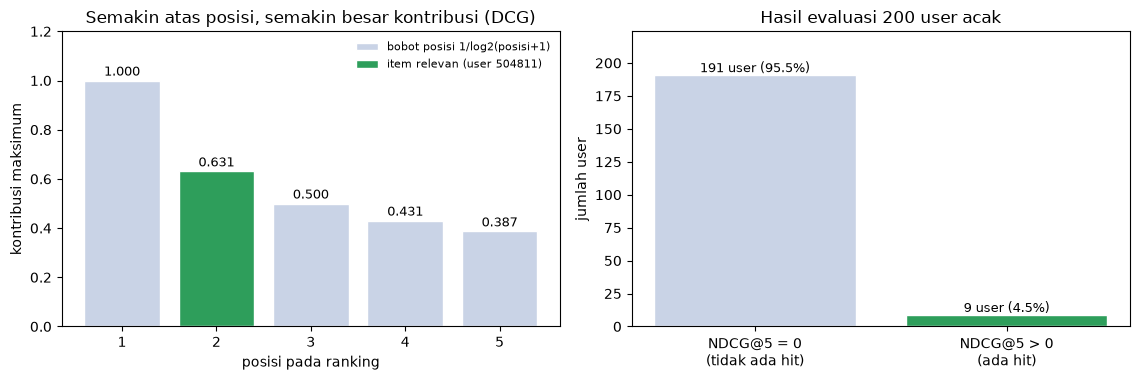

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9))

# kiri: bobot posisi pada DCG
posisi = np.arange(1, 6)
bobot_pos = 1 / np.log2(posisi + 1)
ax1.bar(posisi, bobot_pos, color="#c9d3e6", edgecolor="white", label="bobot posisi 1/log2(posisi+1)")
if len(contoh):
    rel = tt["relevan (rel)"].to_numpy()
    ax1.bar(posisi[rel == 1], bobot_pos[rel == 1], color="#2E9E5B", edgecolor="white",
            label=f"item relevan (user {int(contoh.iloc[0]['user'])})")
for p_, b_ in zip(posisi, bobot_pos):
    ax1.text(p_, b_ + 0.02, f"{b_:.3f}", ha="center", fontsize=9)
ax1.set_xticks(posisi)
ax1.set_xlabel("posisi pada ranking")
ax1.set_ylabel("kontribusi maksimum")
ax1.set_ylim(0, 1.2)
ax1.set_title("Semakin atas posisi, semakin besar kontribusi (DCG)")
ax1.legend(fontsize=8, frameon=False)

# kanan: sebaran NDCG@5 pada user sampel
nol = int((hasil["ndcg"] == 0).sum())
positif = len(hasil) - nol
batang = ax2.bar(["NDCG@5 = 0\n(tidak ada hit)", "NDCG@5 > 0\n(ada hit)"], [nol, positif],
                 color=["#c9d3e6", "#2E9E5B"], edgecolor="white")
for b_, v in zip(batang, [nol, positif]):
    ax2.text(b_.get_x() + b_.get_width() / 2, v + len(hasil) * 0.01, f"{v} user ({v / len(hasil) * 100:.1f}%)",
             ha="center", fontsize=9)
ax2.set_ylim(0, len(hasil) * 1.12)
ax2.set_ylabel("jumlah user")
ax2.set_title(f"Hasil evaluasi {len(hasil)} user acak")

plt.tight_layout()
plt.show()


### Ringkasan hasil

| Bagian | Hasil utama |
|---|---|
| 2.1 no. 1 dan 2 | P1 = 1 sampai 15 Agustus 2015 (265.509 baris), P2 = 16 sampai 20 Agustus 2015 (95.404 baris), disimpan ke `events_train.csv` dan `events_test.csv` |
| 2.1 no. 3 | Subgraph P1: 153.836 `Visitor`, 76.078 `Item`, 265.509 relasi. Graf bipartit, 96,6% relasi `VIEWED` |
| 2.1 no. 4 dan 5 | VSM User 153.836 × 76.078 dan VSM Item 76.078 × 153.836, sparsity 99,9982% |
| 2.1 no. 6 | Proyeksi **Item–Item** lebih efisien dan lebih efektif |
| 2.1 no. 7 dan 8 | Item acuan 45337. Lima item paling mirip ditulis sebagai relasi `SIMILAR_TO` (0 menjadi 5 relasi) |
| 2.2 no. 1 | User 123595. Tiga item iklan: 113754, 132335, 168546 (KNN item-based, k = 5) |
| 2.2 no. 2 | User 123595: Hit@5 = 0 dan NDCG@5 = 0. Rata-rata 200 user: Hit@5 = 0,045 dan NDCG@5 = 0,022 |

**Keterbatasan.** Data interaksi sangat jarang dan hanya mencakup periode pendek, sehingga performa rekomendasi rendah. Peningkatan dapat dicoba dengan periode training yang lebih panjang, atau dengan menambahkan atribut item (misalnya kategori) untuk mengatasi item yang jarang disentuh.

#### Menutup koneksi
Koneksi ke Neo4j ditutup setelah seluruh analisis selesai.

In [25]:
driver.close()
